# Greece and Europe

We compare equivalised disposable income in Greece with the other European countries and territories available in the project data, including Cyprus and Türkiye.

Historical context includes the 2008–09 financial crisis, the 2011–12 euro area debt crisis and COVID-19 in 2020 ([ECB, 2020](https://www.ecb.europa.eu/press/annual-reports-financial-statements/annual/html/ar2020~4960fb81ae.en.html)), alongside the 2022 energy and inflation shock ([ECB, 2022](https://www.ecb.europa.eu/press/annual-reports-financial-statements/annual/html/ecb.ar2022~8ae51d163b.en.html)). These annotations provide context without establishing causation.

Data preparation stays in the EDA notebook.

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter, MultipleLocator
from matplotlib.lines import Line2D

In [2]:
income_data = pd.read_csv("../data/processed/ilc_di03_clean.csv")

In [3]:
# The individual reporting areas in this export match our agreed scope.
# Remove EU and euro-area aggregates, keeping countries and territories.
europe_income = income_data.loc[
    ~income_data["geo_code"].str.startswith(("EU", "EA"))
    & (income_data["sex"] == "T")
    & (income_data["age"] == "TOTAL")].copy()

display(europe_income[["unit", "Unit of measure"]].drop_duplicates().sort_values("unit"))

,unit,Unit of measure
0,EUR,Euro
836,NAC,National currency
1554,PPS,Purchasing power standard (PPS)


In [4]:
# Overview across all units and indicators.
# This does not establish completeness for every individual series.
coverage = (
    europe_income.groupby(["geo_code", "geo_name"])
    .agg(
        first_survey_year=("year", "min"),
        last_survey_year=("year", "max"),
        survey_years=("year", "nunique"),
        rows=("income", "size"),
        non_missing_values=("income", "count")
    )
    .reset_index()
    .sort_values("geo_name"))

display(coverage)

,geo_code,geo_name,first_survey_year,last_survey_year,survey_years,rows,non_missing_values
0,AL,Albania,2017,2025,9,54,54
1,AT,Austria,2003,2025,23,138,138
2,BE,Belgium,2003,2025,23,138,138
3,BG,Bulgaria,2006,2025,20,120,120
14,HR,Croatia,2010,2025,16,96,96
5,CY,Cyprus,2005,2025,21,126,126
6,CZ,Czechia,2005,2025,21,126,126
8,DK,Denmark,2003,2025,23,138,138
9,EE,Estonia,2004,2025,22,132,132
12,FI,Finland,2004,2025,22,132,132


In [5]:
# Counts refer to data rows across units and indicators, not people.
flag_summary = (
    europe_income.loc[europe_income["obs_flag"].notna()]
    .groupby(["geo_code", "geo_name", "year", "obs_flag"])
    .size()
    .reset_index(name="flagged_rows")
    .sort_values(["geo_name", "year"]))

display(flag_summary)

,geo_code,geo_name,year,obs_flag,flagged_rows
0,AT,Austria,2003,b,6
1,AT,Austria,2008,b,6
2,BE,Belgium,2003,b,6
3,BE,Belgium,2019,b,6
4,BG,Bulgaria,2016,b,6
20,HR,Croatia,2023,b,6
21,HR,Croatia,2024,b,6
6,CY,Cyprus,2008,b,6
9,DK,Denmark,2011,b,6
10,DK,Denmark,2020,b,6


### Comparing Greece with other countries

We compare nominal EUR amounts for all ages and sexes. Inflation and national price differences are not adjusted for. Exchange rates can also affect the non-euro series.

For these countries, income year = survey year − 1. Observations flagged `b` are retained, with lines interrupted at breaks ([Eurostat metadata](https://ec.europa.eu/eurostat/cache/metadata/en/ilc_sieusilc.htm)).

Grey bands provide historical context: the 2008–09 financial crisis, 2011–12 euro area debt crisis and COVID-19 in 2020 ([ECB, 2020](https://www.ecb.europa.eu/press/annual-reports-financial-statements/annual/html/ar2020~4960fb81ae.en.html)); and the 2022 energy/inflation shock ([ECB, 2022](https://www.ecb.europa.eu/press/annual-reports-financial-statements/annual/html/ecb.ar2022~8ae51d163b.en.html)). They do not establish causation.

In [6]:
# Reuse these country colours in all subsequent charts.
country_colors = {
    "EL": "#185ABD",  # Greece
    "CY": "#E17C05",  # Cyprus
    "TR": "#C62828",  # Türkiye
    "IT": "#20854E",  # Italy
    "DE": "#7B3F98",  # Germany
    "ES": "#8C4F2B",  # Spain
    "SE": "#C23B83",  # Sweden
    "FR": "#00838F",  # France
    "PT": "#707B12",  # Portugal
    "BG": "#B28A00",  # Bulgaria
    "NO": "#424242",  # Norway
}

In [7]:
# Keep the same line styles in every chart.
line_styles = {"MEAN_EI": "-", "MED_EI": "--"}
indicator_names = {"MEAN_EI": "Mean", "MED_EI": "Median"}

country_names = (
    europe_income.drop_duplicates("geo_code")
    .set_index("geo_code")["geo_name"]
    .to_dict())

In [8]:
# europe_income already contains age=TOTAL and sex=T.
eur_data = europe_income.loc[
    europe_income["geo_code"].isin(country_colors)
    & (europe_income["unit"] == "EUR")
    & europe_income["indicator"].isin(line_styles)
    & europe_income["year"].between(2003, 2025)].copy()

In [9]:
# Apply this calendar-year alignment only to the selected countries.
eur_data["income_year"] = eur_data["year"] - 1

income_years = range(2002, 2025)

In [10]:
# Include every expected country, indicator and year in the coverage check.
expected_columns = pd.MultiIndex.from_product(
    [list(country_colors), list(line_styles)],
    names=["geo_code", "indicator"])

In [11]:
# pivot reshapes the published values without averaging them.
# reindex exposes absent years as NaN; no income values are filled.
income_wide = eur_data.pivot(
    index="income_year",
    columns=["geo_code", "indicator"],
    values="income").reindex(index=income_years, columns=expected_columns)

flag_wide = eur_data.pivot(
    index="income_year",
    columns=["geo_code", "indicator"],
    values="obs_flag").reindex(index=income_years, columns=expected_columns)

missing_check = (
    income_wide.isna().sum().unstack("indicator")
    .rename(columns={
        "MEAN_EI": "mean_missing_years",
        "MED_EI": "median_missing_years"}))

In [12]:
# Exclude a country if either indicator has more than three missing years.
missing_check["included"] = missing_check.max(axis=1) <= 3
display(missing_check.reindex(list(country_colors)))

eligible_codes = missing_check.index[missing_check["included"]].tolist()

comparison_countries = [code for code in country_colors if code != "EL" and code in eligible_codes]

print("Retained flagged observations:")
display(
    eur_data.loc[
        eur_data["geo_code"].isin(eligible_codes)
        & eur_data["obs_flag"].notna(),
        ["geo_name", "year", "income_year", "indicator", "obs_flag"]
    ].sort_values(["geo_name", "year", "indicator"]))

indicator,mean_missing_years,median_missing_years,included
geo_code,,,
EL,0,0,True
CY,2,2,True
TR,3,3,True
IT,1,1,True
DE,2,2,True
ES,1,1,True
SE,1,1,True
FR,1,1,True
PT,1,1,True


Retained flagged observations:


,geo_name,year,income_year,indicator,obs_flag
65,Bulgaria,2016,2015,MEAN_EI,b
2382,Bulgaria,2016,2015,MED_EI,b
96,Cyprus,2008,2007,MEAN_EI,b
2413,Cyprus,2008,2007,MED_EI,b
386,France,2004,2003,MEAN_EI,b
2703,France,2004,2003,MED_EI,b
390,France,2008,2007,MEAN_EI,b
2707,France,2008,2007,MED_EI,b
402,France,2020,2019,MEAN_EI,b
2719,France,2020,2019,MED_EI,b


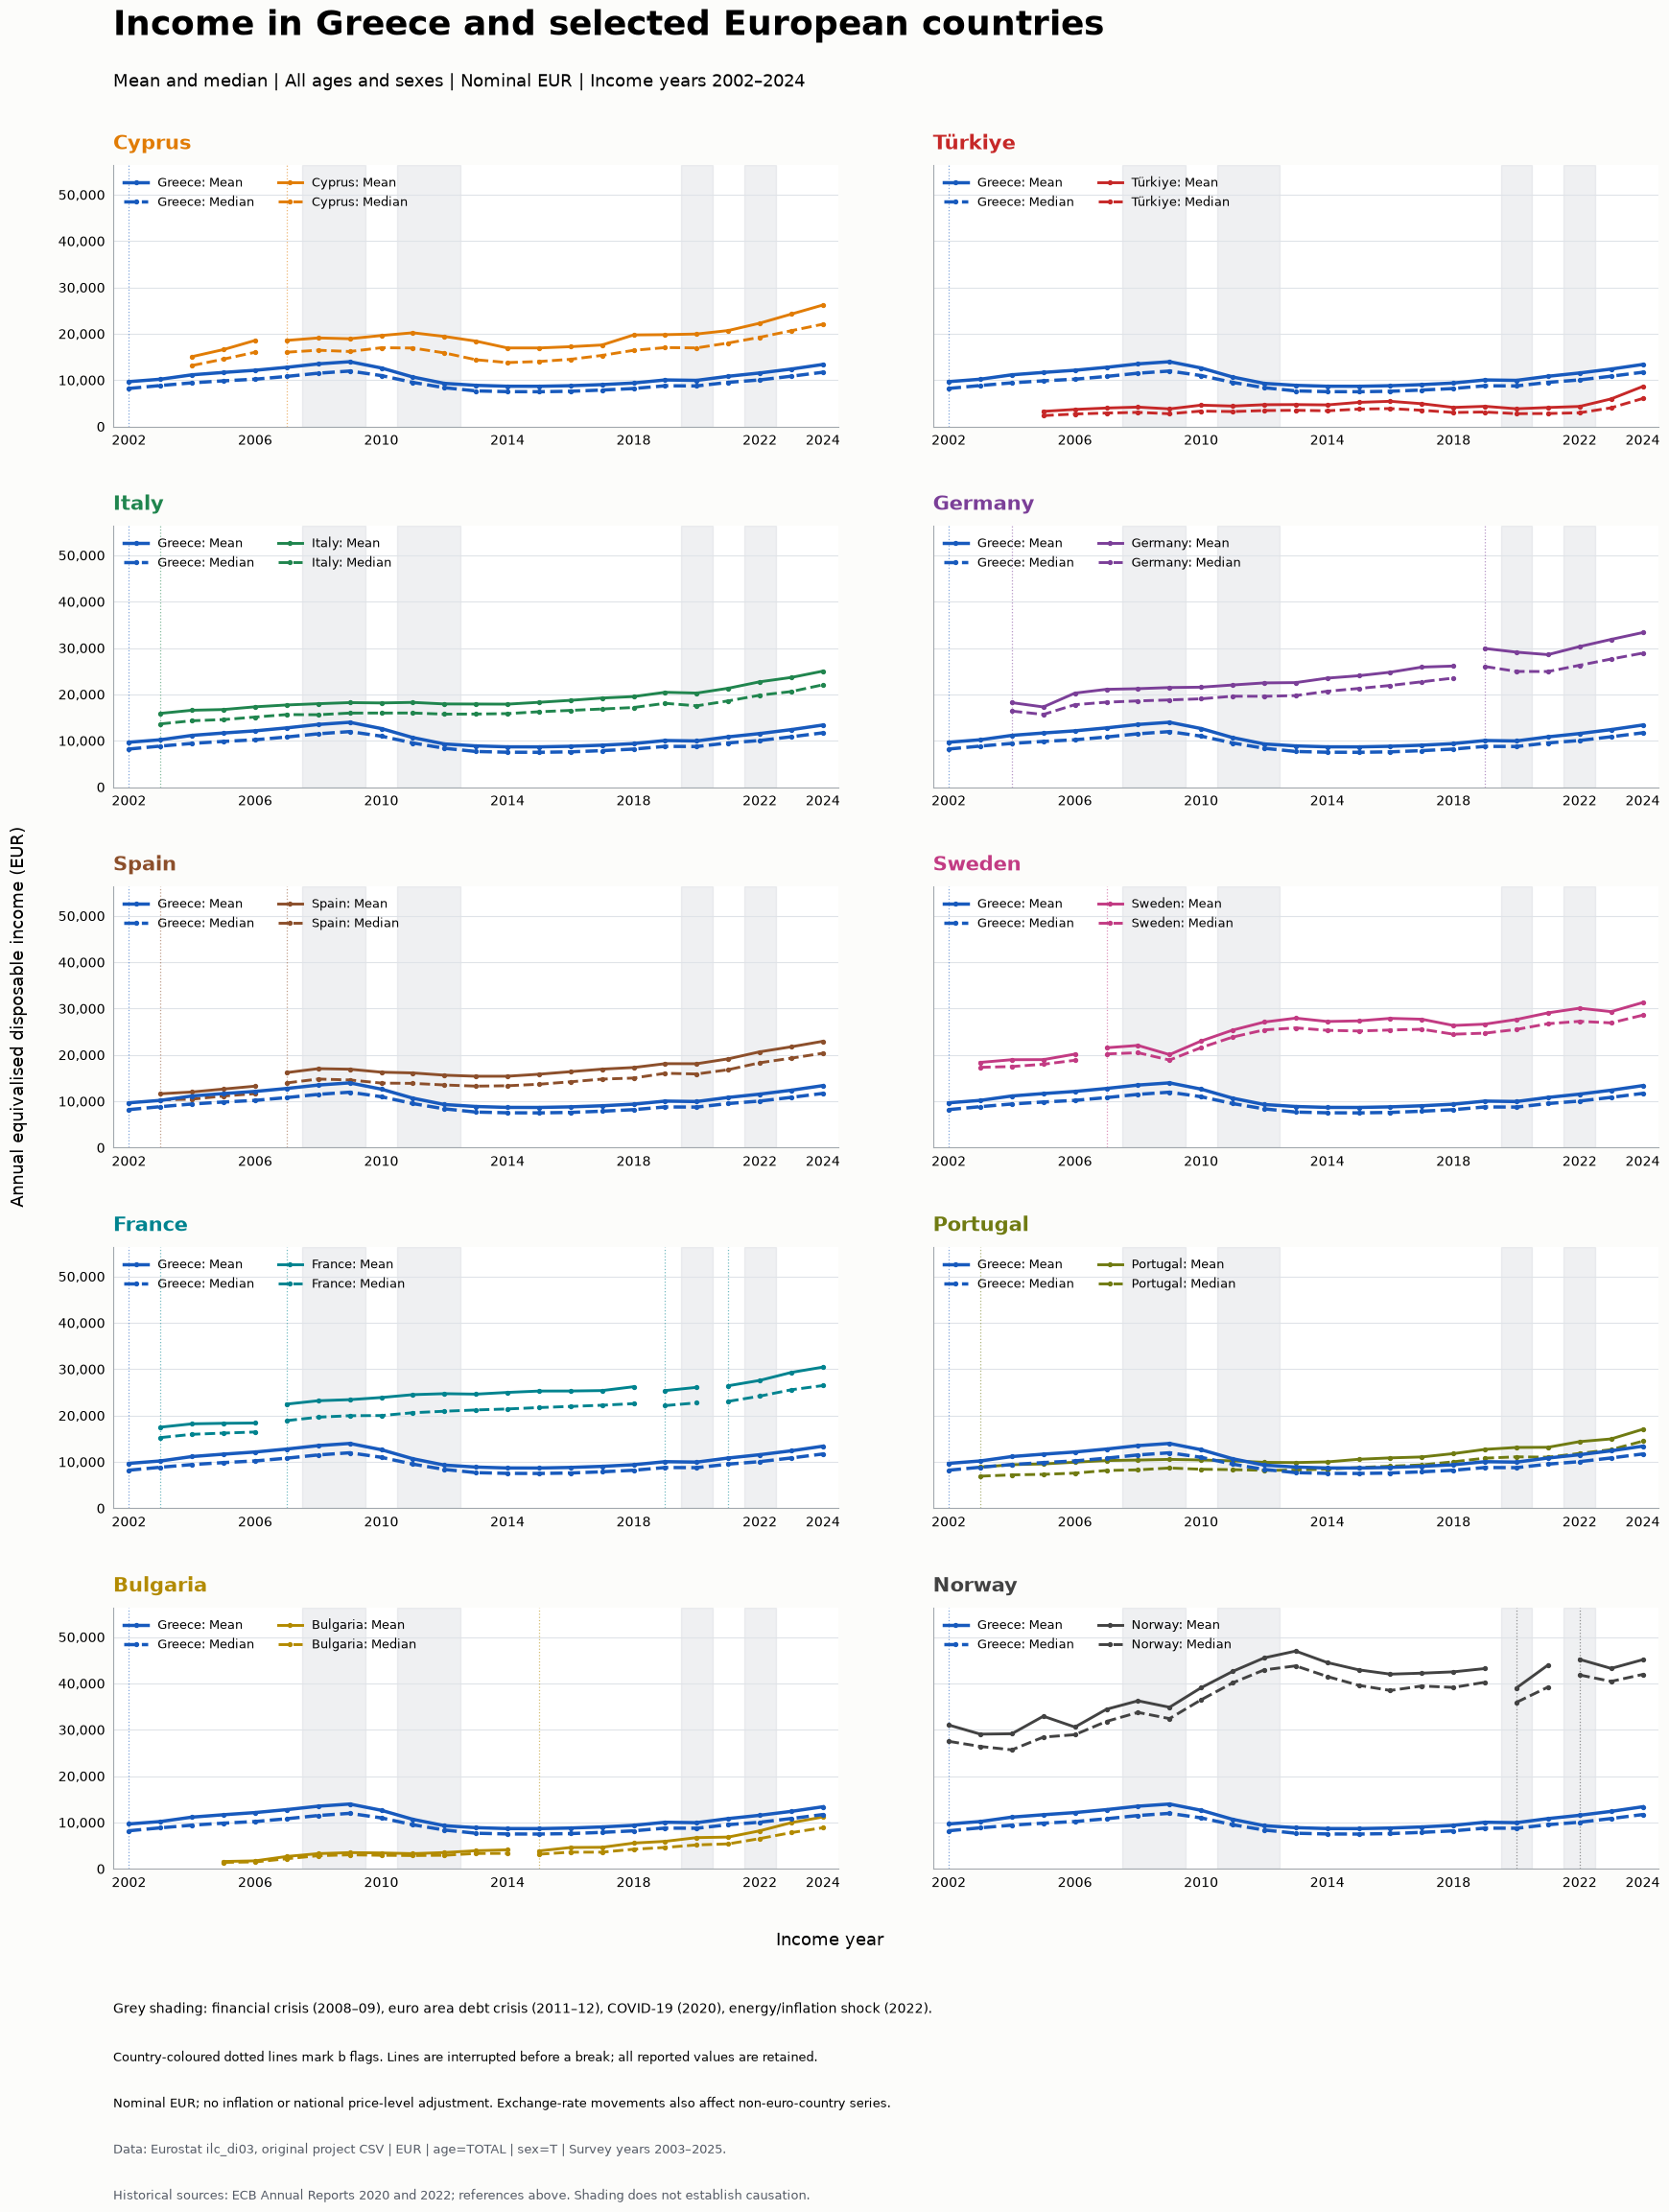

In [13]:
historical_periods = [
    (2008, 2009),
    (2011, 2012),
    (2020, 2020),
    (2022, 2022)]

fig, axes = plt.subplots(
    5, 2,
    figsize=(18, 24),
    sharex=True,
    sharey=True,
    facecolor="#FCFCFA")

fig.subplots_adjust(
    left=0.085, right=0.98,
    top=0.91, bottom=0.17,
    hspace=0.38, wspace=0.13)

# Use one common vertical scale for all comparisons.
y_limit = eur_data.loc[eur_data["geo_code"].isin(eligible_codes), "income"].max() * 1.20

for ax, comparison_code in zip(axes.flat, comparison_countries):
    ax.set_facecolor("white")

    for start, end in historical_periods:
        # Each annual observation sits at the centre of its calendar-year band.
        ax.axvspan(
            start - 0.5, end + 0.5,
            color="#BBC2CB", alpha=0.23, zorder=0
        )

    for code in ["EL", comparison_code]:
        for indicator, line_style in line_styles.items():
            values = income_wide[(code, indicator)]
            flags = flag_wide[(code, indicator)].fillna("")

            # Each b flag starts a new segment; its income value is retained.
            segment_ids = flags.str.contains("b", regex=False).cumsum()

            for segment_number, (_, segment) in enumerate(
                values.groupby(segment_ids)
            ):
                ax.plot(
                    segment.index,
                    segment,
                    color=country_colors[code],
                    linestyle=line_style,
                    linewidth=2.5 if code == "EL" else 2.1,
                    marker="o",
                    markersize=2.8,
                    label=(
                        f"{country_names[code]}: {indicator_names[indicator]}"
                        if segment_number == 0 else None
                    ),
                    zorder=4 if code == "EL" else 3
                )

        # Mark each break year once, using the affected country's colour.
        break_years = eur_data.loc[
            (eur_data["geo_code"] == code)
            & eur_data["obs_flag"].fillna("").str.contains("b", regex=False),
            "income_year"
        ].unique()

        for break_year in break_years:
            ax.axvline(
                break_year,
                color=country_colors[code],
                linestyle=":",
                linewidth=0.9,
                alpha=0.55,
                zorder=1
            )

    ax.set_title(
        country_names[comparison_code],
        loc="left", fontsize=15, fontweight="bold",
        color=country_colors[comparison_code], pad=12
    )

    ax.set_xlim(2001.5, 2024.5)
    ax.set_ylim(0, y_limit)
    ax.set_xticks([2002, 2006, 2010, 2014, 2018, 2022, 2024])
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

    ax.tick_params(
        axis="both", labelsize=10, length=0, pad=6
    )
    ax.tick_params(axis="x", labelbottom=True)

    ax.grid(axis="y", color="#DFE3E8", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#A2A8AE")

    ax.legend(
        loc="upper left",
        ncols=2,
        frameon=False,
        fontsize=9
    )

# Hide unused panels if any country fails the coverage rule.
for ax in axes.flat[len(comparison_countries):]:
    ax.set_visible(False)

fig.suptitle(
    "Income in Greece and selected European countries",
    x=0.085, y=0.978, ha="left", va="top",
    fontsize=26, fontweight="bold")

fig.text(
    0.085, 0.95,
    "Mean and median | All ages and sexes | Nominal EUR | Income years 2002–2024",
    fontsize=13, va="top")

fig.supxlabel("Income year", y=0.135, fontsize=13)
fig.supylabel(
    "Annual equivalised disposable income (EUR)",
    x=0.025, y=0.54, fontsize=13)

fig.text(
    0.085, 0.112,
    "Grey shading: financial crisis (2008–09), euro area debt crisis (2011–12), "
    "COVID-19 (2020), energy/inflation shock (2022).",
    fontsize=10, va="top")

fig.text(
    0.085, 0.091,
    "Country-coloured dotted lines mark b flags. Lines are interrupted before "
    "a break; all reported values are retained.",
    fontsize=9.5, va="top")

fig.text(
    0.085, 0.071,
    "Nominal EUR; no inflation or national price-level adjustment. "
    "Exchange-rate movements also affect non-euro-country series.",
    fontsize=9.5, va="top")

fig.text(
    0.085, 0.051,
    "Data: Eurostat ilc_di03, original project CSV | EUR | age=TOTAL | sex=T | "
    "Survey years 2003–2025.",
    fontsize=9.5, color="#555B66", va="top")

fig.text(
    0.085, 0.031,
    "Historical sources: ECB Annual Reports 2020 and 2022; references above. "
    "Shading does not establish causation.",
    fontsize=9.5, color="#555B66", va="top")

fig.savefig(
    "../reports/figures/greece_europe_income_mean_median_eur.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

### Median income across countries

Columns show survey years. Historical income-period exceptions apply to Ireland and the United Kingdom ([Eurostat metadata](https://ec.europa.eu/eurostat/cache/metadata/en/ilc_sieusilc.htm), [methodology](https://ec.europa.eu/eurostat/statistics-explained/index.php?title=EU_statistics_on_income_and_living_conditions_(EU-SILC)_methodology_-_distribution_of_income)).

All available countries are retained. Grey means missing; `b` indicates a break in series and `p` provisional data. Amounts are nominal EUR.

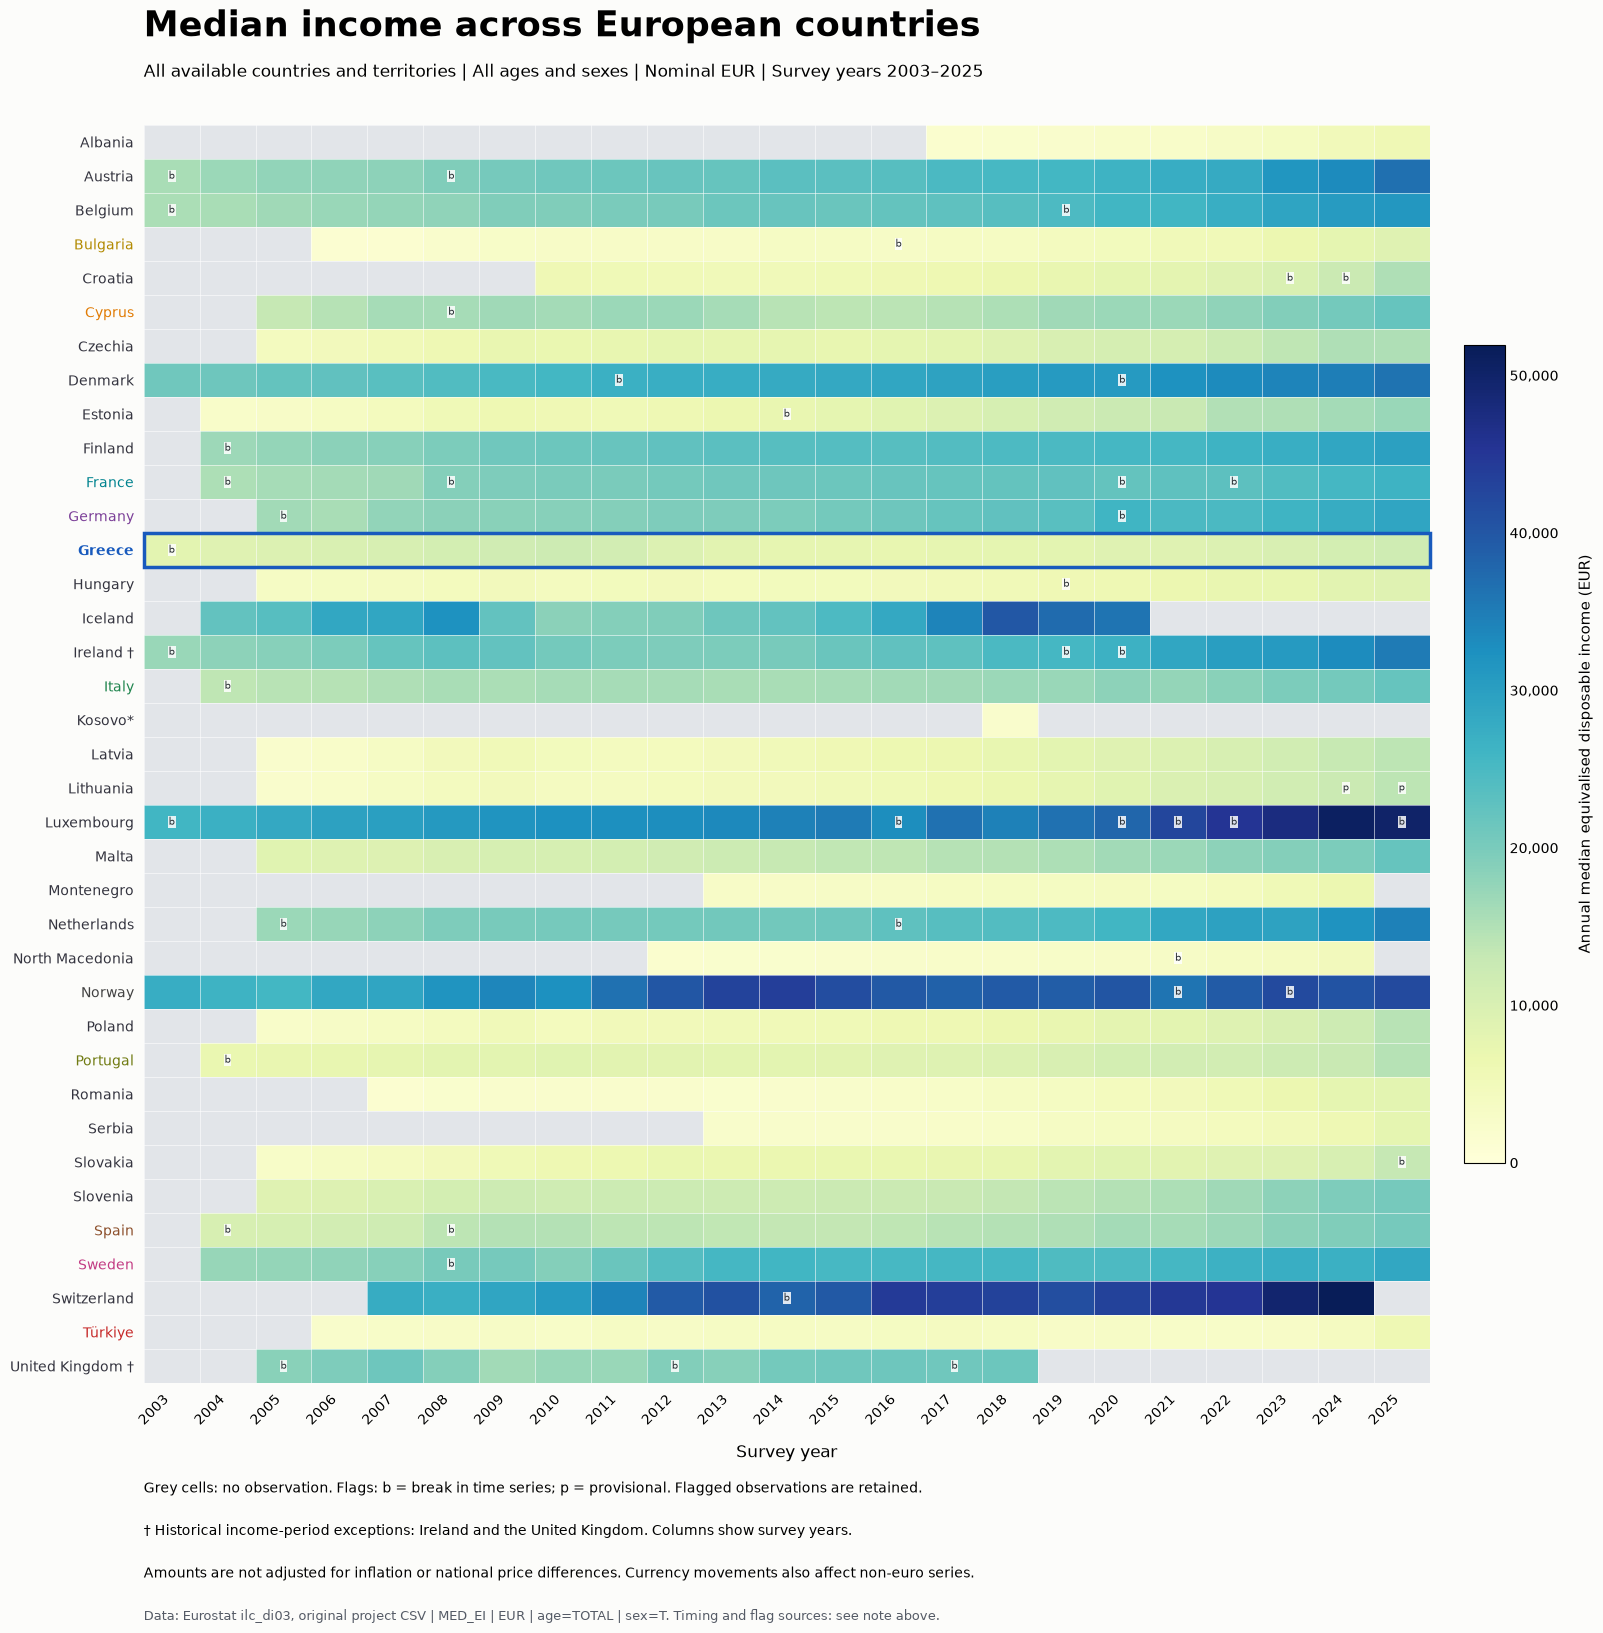

In [14]:
from matplotlib.patches import Rectangle
from matplotlib.ticker import StrMethodFormatter

# Use all countries, without the previous missing-year exclusion rule.
median_all = europe_income.loc[
    (europe_income["indicator"] == "MED_EI")
    & (europe_income["unit"] == "EUR")
    & europe_income["year"].between(2003, 2025)].copy()

survey_years = list(range(2003, 2026))

# Keep countries in alphabetical order rather than ranking different years.
country_order = (
    median_all.sort_values("geo_name")["geo_code"]
    .drop_duplicates()
    .tolist())

# Reshape the published values without aggregation or filling missing income.
median_values = median_all.pivot(index="geo_code", columns="year", values="income").reindex(index=country_order, columns=survey_years)

# Fill only missing flag labels, leaving missing income unchanged.
median_flags = median_all.pivot(index="geo_code", columns="year", values="obs_flag").reindex(index=country_order, columns=survey_years).fillna("")

# A dagger identifies historical income-period exceptions.
country_labels = [
    country_names[code] + (" †" if code in ["IE", "UK"] else "")
    for code in country_order]

# One shared colour scale represents income across all countries and years.
cmap = plt.colormaps["YlGnBu"].with_extremes(bad="#E2E5E9")

fig, ax = plt.subplots(figsize=(18, 17), facecolor="#FCFCFA")
fig.subplots_adjust(left=0.18, right=0.94, top=0.91, bottom=0.17)

heatmap = ax.imshow(
    median_values.to_numpy(dtype=float),
    cmap=cmap,
    vmin=0,
    aspect="auto",
    interpolation="nearest")

ax.set_xticks(
    range(len(survey_years)),
    labels=survey_years,
    rotation=45,
    ha="right",
    fontsize=10)
ax.set_yticks(
    range(len(country_order)),
    labels=country_labels,
    fontsize=10)

ax.set_xlabel("Survey year", fontsize=12, labelpad=12)
ax.tick_params(axis="both", length=0, pad=7)
ax.grid(False)
ax.spines[["top", "right", "bottom", "left"]].set_visible(False)

# Separate cells with thin white borders.
for row in range(len(country_order) + 1):
    ax.axhline(row - 0.5, color="white", linewidth=0.4)

for col in range(len(survey_years) + 1):
    ax.axvline(col - 0.5, color="white", linewidth=0.4)

# Preserve existing country colours in the labels.
# Countries without an assigned colour use neutral grey.
for tick, code in zip(ax.get_yticklabels(), country_order):
    tick.set_color(country_colors.get(code, "#34343F"))
    if code == "EL":
        tick.set_fontweight("bold")

# Cell centres start at zero; borders sit halfway between centres.
greece_row = country_order.index("EL")
ax.add_patch(
    Rectangle(
        (-0.5, greece_row - 0.5),
        width=len(survey_years),
        height=1,
        fill=False,
        edgecolor=country_colors["EL"],
        linewidth=2.5,
        clip_on=False,
        zorder=5
    )
)

# Show source flags inside their corresponding cells.
for row, code in enumerate(country_order):
    for col, year in enumerate(survey_years):
        flag = median_flags.loc[code, year]

        if flag != "":
            ax.text(
                col, row, flag,
                ha="center", va="center",
                fontsize=7, color="#252A30",
                bbox={
                    "facecolor": "white",
                    "edgecolor": "none",
                    "alpha": 0.85,
                    "pad": 0.6
                },
                zorder=4)

colorbar = fig.colorbar(
    heatmap, ax=ax,
    fraction=0.035, pad=0.025, shrink=0.65,
    format=StrMethodFormatter("{x:,.0f}"))
colorbar.set_label(
    "Annual median equivalised disposable income (EUR)",
    fontsize=11, labelpad=14)
colorbar.ax.tick_params(labelsize=10, length=0)

fig.suptitle(
    "Median income across European countries",
    x=0.18, y=0.978, ha="left", va="top",
    fontsize=25, fontweight="bold")
fig.text(
    0.18, 0.946,
    "All available countries and territories | All ages and sexes | "
    "Nominal EUR | Survey years 2003–2025",
    fontsize=12, va="top")

fig.text(
    0.18, 0.112,
    "Grey cells: no observation. Flags: b = break in time series; "
    "p = provisional. Flagged observations are retained.",
    fontsize=10, va="top")
fig.text(
    0.18, 0.087,
    "† Historical income-period exceptions: Ireland and the United Kingdom. "
    "Columns show survey years.",
    fontsize=10, va="top")
fig.text(
    0.18, 0.062,
    "Amounts are not adjusted for inflation or national price differences. "
    "Currency movements also affect non-euro series.",
    fontsize=10, va="top")
fig.text(
    0.18, 0.037,
    "Data: Eurostat ilc_di03, original project CSV | MED_EI | EUR | "
    "age=TOTAL | sex=T. Timing and flag sources: see note above.",
    fontsize=9, color="#555B66", va="top")

fig.savefig(
    "../reports/figures/europe_median_income_heatmap_eur.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

### Housing cost overburden across countries

The heatmap shows the percentage of people whose household housing costs exceed 40% of disposable income. Both costs and income are net of housing allowances ([Eurostat definition](https://ec.europa.eu/eurostat/statistics-explained/index.php?title=Glossary:Housing_cost_overburden_rate)).

Grey cells indicate missing observations. All source flags are retained.

In [18]:
housing_europe_data = pd.read_csv("../data/processed/ilc_lvho07a_europe.csv")

survey_years = list(range(2003, 2026))

In [19]:
# Alphabetical country order, matching the approach used for income.
housing_names = (
    housing_europe_data[["geo_code", "geo_name"]]
    .drop_duplicates()
    .sort_values("geo_name")
    .set_index("geo_code")["geo_name"])

housing_order = housing_names.index.tolist()

In [20]:
# Keep survey years as published. Missing years remain NaN.
housing_values = housing_europe_data.pivot(
    index="geo_code",
    columns="year",
    values="housing_overburden_rate"
).reindex(index=housing_order, columns=survey_years)

In [21]:
# Fill only missing flag labels, leaving the measured values unchanged.
housing_flags = housing_europe_data.pivot(
    index="geo_code",
    columns="year",
    values="obs_flag"
).reindex(index=housing_order, columns=survey_years).fillna("")

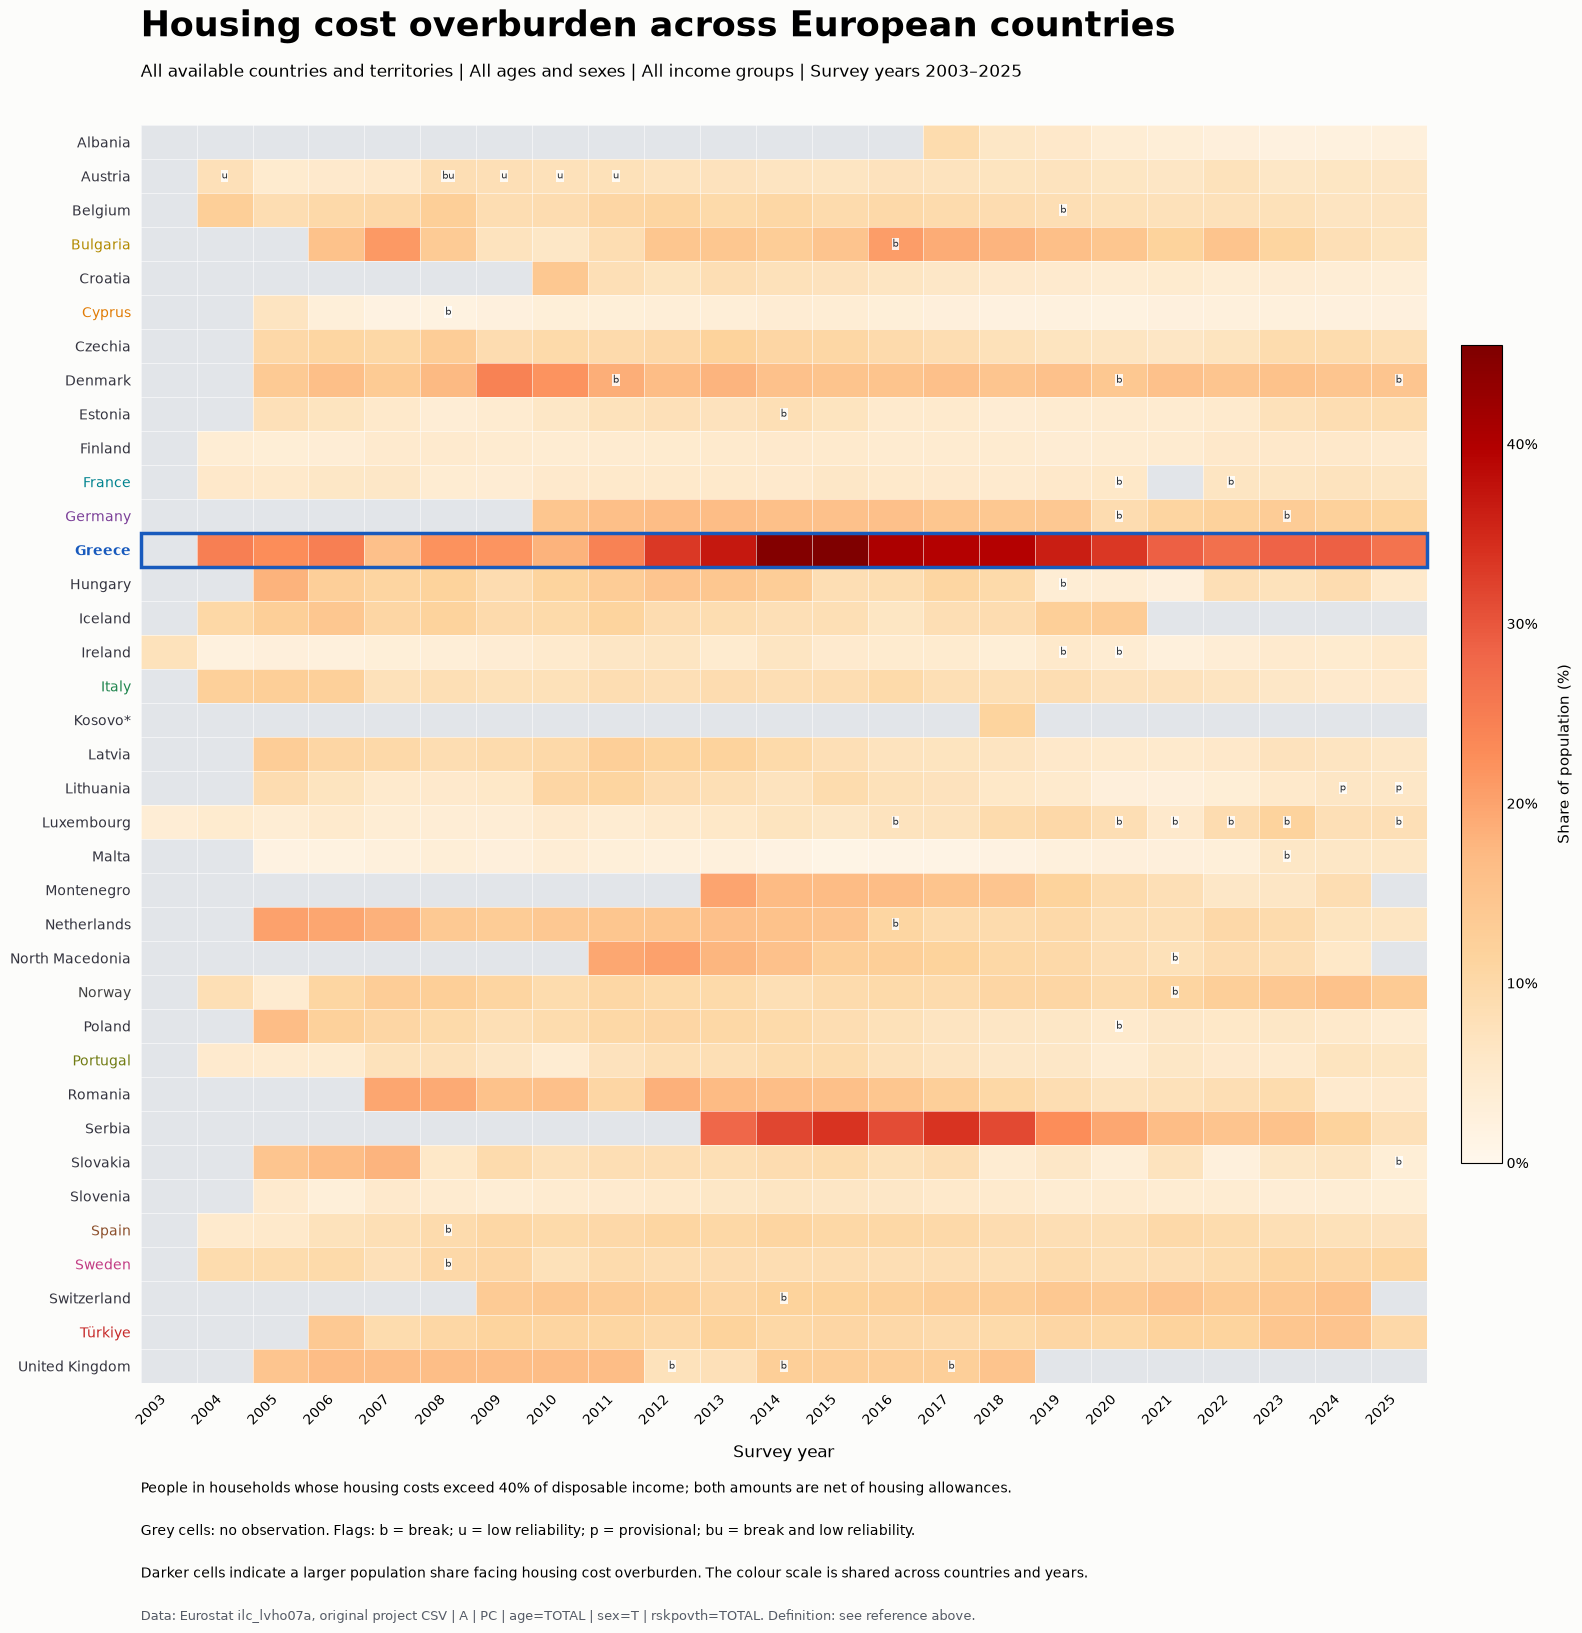

In [22]:
# One shared scale represents population percentages across the entire chart.
cmap = plt.colormaps["OrRd"].with_extremes(bad="#E2E5E9")

fig, ax = plt.subplots(figsize=(18, 17), facecolor="#FCFCFA")
fig.subplots_adjust(left=0.18, right=0.94, top=0.91, bottom=0.17)

heatmap = ax.imshow(
    housing_values.to_numpy(dtype=float),
    cmap=cmap,
    vmin=0,
    aspect="auto",
    interpolation="nearest")

ax.set_xticks(
    range(len(survey_years)),
    labels=survey_years,
    rotation=45,
    ha="right",
    fontsize=10)
ax.set_yticks(
    range(len(housing_order)),
    labels=housing_names.tolist(),
    fontsize=10)

ax.set_xlabel("Survey year", fontsize=12, labelpad=12)
ax.tick_params(axis="both", length=0, pad=7)
ax.grid(False)
ax.spines[["top", "right", "bottom", "left"]].set_visible(False)

# Separate cells with thin white borders.
for row in range(len(housing_order) + 1):
    ax.axhline(row - 0.5, color="white", linewidth=0.4)

for col in range(len(survey_years) + 1):
    ax.axvline(col - 0.5, color="white", linewidth=0.4)

# Reuse the existing country colours in the labels.
for tick, code in zip(ax.get_yticklabels(), housing_order):
    tick.set_color(country_colors.get(code, "#34343F"))
    if code == "EL":
        tick.set_fontweight("bold")

# Highlight Greece without changing the colour representing its values.
greece_row = housing_order.index("EL")
ax.add_patch(
    Rectangle(
        (-0.5, greece_row - 0.5),
        width=len(survey_years),
        height=1,
        fill=False,
        edgecolor=country_colors["EL"],
        linewidth=2.5,
        clip_on=False,
        zorder=5))

# Preserve complete flag strings, including combined flags such as bu.
for row, code in enumerate(housing_order):
    for col, year in enumerate(survey_years):
        flag = housing_flags.loc[code, year]

        if flag != "":
            ax.text(
                col, row, flag,
                ha="center", va="center",
                fontsize=7, color="#252A30",
                bbox={
                    "facecolor": "white",
                    "edgecolor": "none",
                    "alpha": 0.85,
                    "pad": 0.6
                },
                zorder=4)

# Values are already percentages: 20 means 20%, not 0.20.
colorbar = fig.colorbar(heatmap, ax=ax, fraction=0.035, pad=0.025, shrink=0.65, format=StrMethodFormatter("{x:.0f}%"))
colorbar.set_label("Share of population (%)", fontsize=11, labelpad=14)
colorbar.ax.tick_params(labelsize=10, length=0)

fig.suptitle(
    "Housing cost overburden across European countries",
    x=0.18, y=0.978, ha="left", va="top",
    fontsize=25, fontweight="bold")
fig.text(
    0.18, 0.946,
    "All available countries and territories | All ages and sexes | "
    "All income groups | Survey years 2003–2025",
    fontsize=12, va="top")

fig.text(
    0.18, 0.112,
    "People in households whose housing costs exceed 40% of disposable income; "
    "both amounts are net of housing allowances.",
    fontsize=10, va="top")
fig.text(
    0.18, 0.087,
    "Grey cells: no observation. Flags: b = break; u = low reliability; "
    "p = provisional; bu = break and low reliability.",
    fontsize=10, va="top")
fig.text(
    0.18, 0.062,
    "Darker cells indicate a larger population share facing housing cost overburden. "
    "The colour scale is shared across countries and years.",
    fontsize=10, va="top")
fig.text(
    0.18, 0.037,
    "Data: Eurostat ilc_lvho07a, original project CSV | A | PC | "
    "age=TOTAL | sex=T | rskpovth=TOTAL. Definition: see reference above.",
    fontsize=9, color="#555B66", va="top")

fig.savefig(
    "../reports/figures/europe_housing_cost_overburden_heatmap.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

### Income and housing pressure: 2024

We match the two published indicators by country and survey year. Income normally refers to 2023; housing-cost and income components can have different reference periods ([income metadata](https://ec.europa.eu/eurostat/cache/metadata/en/ilc_sieusilc.htm), [housing methodology](https://ec.europa.eu/eurostat/statistics-explained/index.php?title=EU_statistics_on_income_and_living_conditions_(EU-SILC)_methodology_-_housing_conditions)).

Each point represents a country with both values available. Income is nominal EUR. Source flags are retained. This is a descriptive comparison between countries.

In [23]:
survey_year = 2024

# Start with every country, including those missing from both 2024 selections.
country_list = (europe_income[["geo_code", "geo_name"]].drop_duplicates().copy())
country_list["year"] = survey_year

income_2024 = europe_income.loc[
    (europe_income["year"] == survey_year)
    & (europe_income["unit"] == "EUR")
    & (europe_income["indicator"] == "MED_EI"),
    ["geo_code", "year", "income", "obs_flag"]
].rename(columns={
    "income": "median_income_eur",
    "obs_flag": "income_flag"})

housing_2024 = housing_europe_data.loc[
    housing_europe_data["year"] == survey_year,
    ["geo_code", "year", "housing_overburden_rate", "obs_flag"]
].rename(columns={"obs_flag": "housing_flag"})

In [24]:
# Match the same country and survey year, preserving each source's flags.
comparison_2024 = country_list.merge(
    income_2024,
    on=["geo_code", "year"],
    how="left")

comparison_2024 = comparison_2024.merge(
    housing_2024,
    on=["geo_code", "year"],
    how="left")

In [25]:
# A point requires both numerical values. Flags do not cause exclusion.
has_both_values = comparison_2024[["median_income_eur", "housing_overburden_rate"]].notna().all(axis=1)

print("Excluded countries: at least one 2024 value is unavailable.")
display(
    comparison_2024.loc[
        ~has_both_values,
        ["geo_code", "geo_name", "median_income_eur", "housing_overburden_rate"]
    ].sort_values("geo_name"))

scatter_2024 = (
    comparison_2024.loc[has_both_values]
    .sort_values("median_income_eur")
    .copy())

print("Countries included:", len(scatter_2024))
display(
    scatter_2024[
        [
            "geo_code", "geo_name", "median_income_eur",
            "housing_overburden_rate", "income_flag", "housing_flag"
        ]
    ].sort_values("geo_name"))

Excluded countries: at least one 2024 value is unavailable.


,geo_code,geo_name,median_income_eur,housing_overburden_rate
17,IS,Iceland,NaN,NaN
36,XK,Kosovo*,NaN,NaN
35,UK,United Kingdom,NaN,NaN


Countries included: 34


,geo_code,geo_name,median_income_eur,housing_overburden_rate,income_flag,housing_flag
0,AL,Albania,4968.0,2.3,NaN,NaN
1,AT,Austria,33210.0,6.3,NaN,NaN
2,BE,Belgium,30446.0,6.7,NaN,NaN
3,BG,Bulgaria,7811.0,8.0,NaN,NaN
14,HR,Croatia,12344.0,3.7,b,NaN
5,CY,Cyprus,20666.0,2.4,NaN,NaN
6,CZ,Czechia,15133.0,9.2,NaN,NaN
8,DK,Denmark,34843.0,14.6,NaN,NaN
9,EE,Estonia,16140.0,8.6,NaN,NaN
12,FI,Finland,28693.0,5.4,NaN,NaN


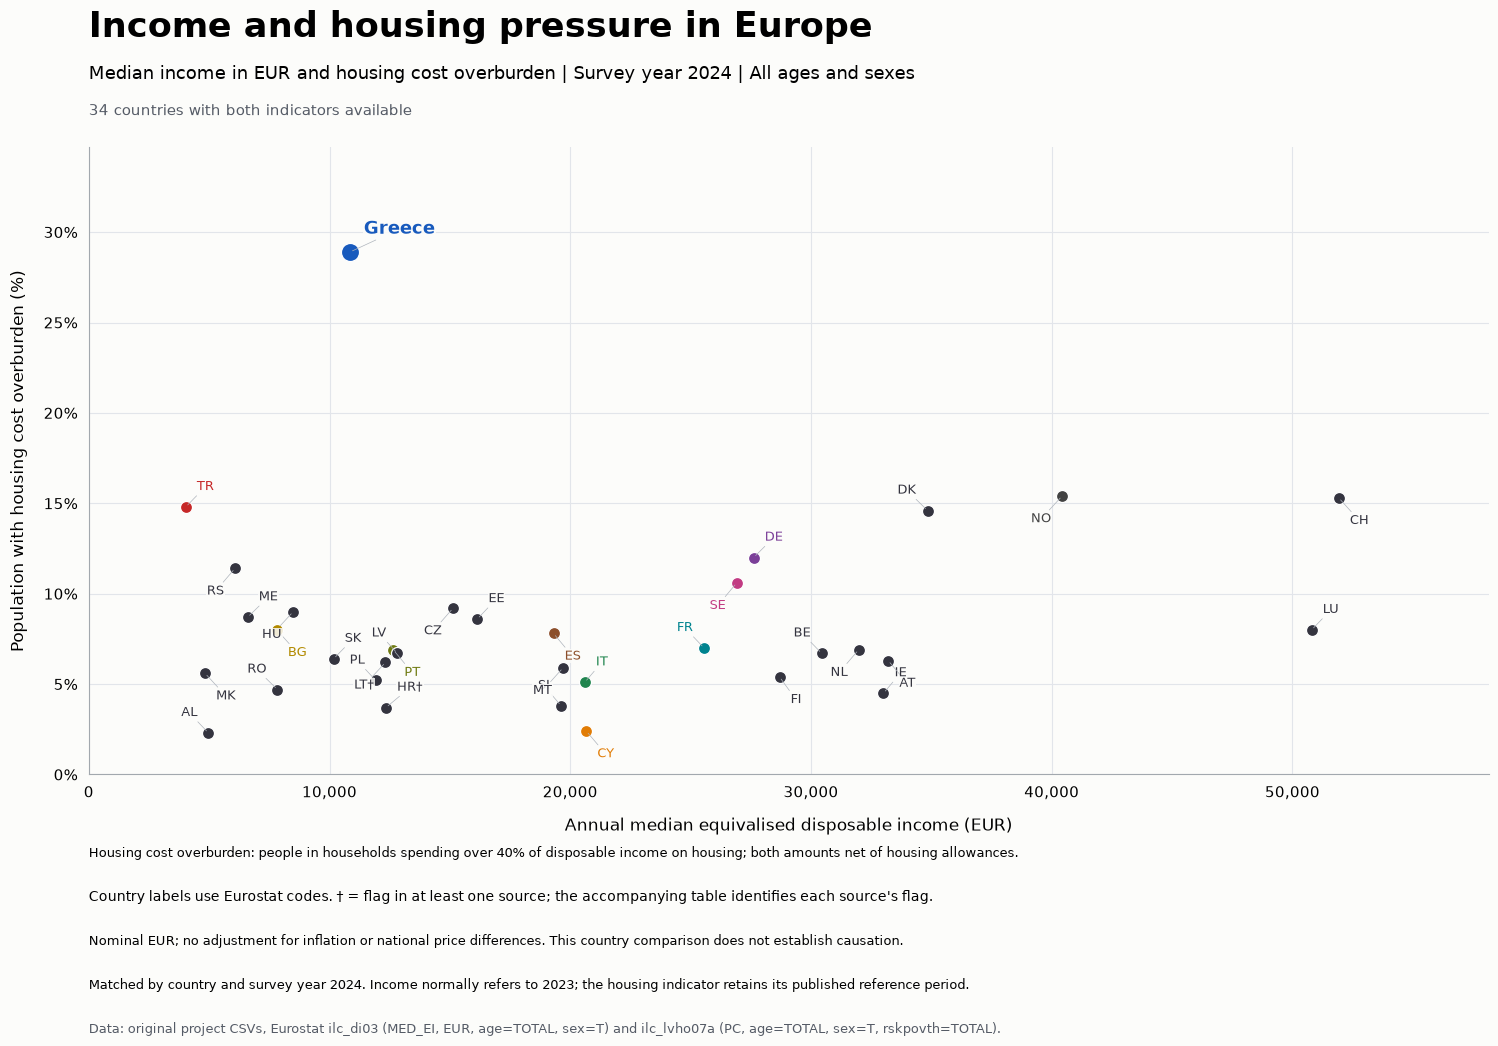

In [26]:
fig, ax = plt.subplots(figsize=(16, 11), facecolor="#FCFCFA")
fig.subplots_adjust(left=0.09, right=0.965, top=0.84, bottom=0.27)
ax.set_facecolor("#FCFCFA")

# Alternate label positions to reduce crowding without moving data points.
label_offsets = [(8, 10), (8, -12), (-8, 10), (-8, -12)]

for i, row in enumerate(scatter_2024.itertuples(index=False)):
    is_greece = row.geo_code == "EL"
    color = country_colors.get(row.geo_code, "#34343F")

    ax.scatter(
        row.median_income_eur,
        row.housing_overburden_rate,
        s=170 if is_greece else 75,
        color=color,
        edgecolors="white",
        linewidths=0.9,
        zorder=4 if is_greece else 3)

    # The dagger preserves the distinction between observed and flagged data.
    flagged = pd.notna(row.income_flag) or pd.notna(row.housing_flag)

    label = "Greece" if is_greece else row.geo_code
    if flagged:
        label += "†"

    dx, dy = (10, 10) if is_greece else label_offsets[i % 4]

    ax.annotate(
        label,
        xy=(row.median_income_eur, row.housing_overburden_rate),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="left" if dx > 0 else "right",
        va="bottom" if dy > 0 else "top",
        fontsize=13 if is_greece else 9,
        fontweight="bold" if is_greece else "normal",
        color=color,
        arrowprops={
            "arrowstyle": "-",
            "color": "#AEB4BC",
            "linewidth": 0.5
        },
        bbox={
            "facecolor": "#FCFCFA",
            "edgecolor": "none",
            "alpha": 0.85,
            "pad": 0.5
        },
        zorder=5)

ax.set_xlim(0, scatter_2024["median_income_eur"].max() * 1.12)
ax.set_ylim(0, scatter_2024["housing_overburden_rate"].max() * 1.20)

ax.set_xlabel("Annual median equivalised disposable income (EUR)", fontsize=12, labelpad=12)
ax.set_ylabel("Population with housing cost overburden (%)", fontsize=12, labelpad=12)

ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))

ax.tick_params(axis="both", labelsize=11, length=0, pad=8)
ax.grid(color="#E2E5EA", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#A2A8AE")

fig.suptitle(
    "Income and housing pressure in Europe",
    x=0.09, y=0.965, ha="left", va="top",
    fontsize=25, fontweight="bold")
fig.text(
    0.09, 0.915,
    "Median income in EUR and housing cost overburden | "
    "Survey year 2024 | All ages and sexes",
    fontsize=13, va="top")
fig.text(
    0.09, 0.88,
    f"{len(scatter_2024)} countries with both indicators available",
    fontsize=11, color="#555B66", va="top")

fig.text(
    0.09, 0.205,
    "Housing cost overburden: people in households spending over 40% of disposable "
    "income on housing; both amounts net of housing allowances.",
    fontsize=9.5, va="top")
fig.text(
    0.09, 0.165,
    "Country labels use Eurostat codes. † = flag in at least one source; "
    "the accompanying table identifies each source's flag.",
    fontsize=10, va="top")
fig.text(
    0.09, 0.125,
    "Nominal EUR; no adjustment for inflation or national price differences. "
    "This country comparison does not establish causation.",
    fontsize=9.5, va="top")
fig.text(
    0.09, 0.085,
    "Matched by country and survey year 2024. Income normally refers to 2023; "
    "the housing indicator retains its published reference period.",
    fontsize=9.5, va="top")
fig.text(
    0.09, 0.045,
    "Data: original project CSVs, Eurostat ilc_di03 (MED_EI, EUR, age=TOTAL, sex=T) "
    "and ilc_lvho07a (PC, age=TOTAL, sex=T, rskpovth=TOTAL).",
    fontsize=9, color="#555B66", va="top")

fig.savefig(
    "../reports/figures/europe_median_income_housing_overburden_2024.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

In [27]:
housing_group_data = pd.read_csv("../data/processed/ilc_lvho07a_europe_income_groups.csv")

housing_groups_2024 = housing_group_data.loc[housing_group_data["year"] == 2024].copy()

housing_group_rates_2024 = housing_groups_2024.pivot(
    index=["geo_code", "geo_name"],
    columns="rskpovth",
    values="housing_overburden_rate"
).reindex(columns=["B_60", "A_60"])

In [28]:
# Include countries with both rates, retaining flagged observations.
housing_group_plot_2024 = (
    housing_group_rates_2024
    .dropna(subset=["B_60", "A_60"])
    .sort_values("B_60", ascending=False))

housing_group_flags_2024 = housing_groups_2024.pivot(
    index=["geo_code", "geo_name"],
    columns="rskpovth",
    values="obs_flag"
).reindex(
    index=housing_group_plot_2024.index,
    columns=["B_60", "A_60"])

print("Countries included:", len(housing_group_plot_2024))

display(
    housing_groups_2024.loc[
        housing_groups_2024["obs_flag"].notna(),
        [
            "geo_name", "rskpovth", "housing_overburden_rate",
            "obs_flag", "flag_description"]])

Countries included: 34


,geo_name,rskpovth,housing_overburden_rate,obs_flag,flag_description
737,Lithuania,A_60,1.7,p,provisional
758,Lithuania,B_60,22.5,p,provisional


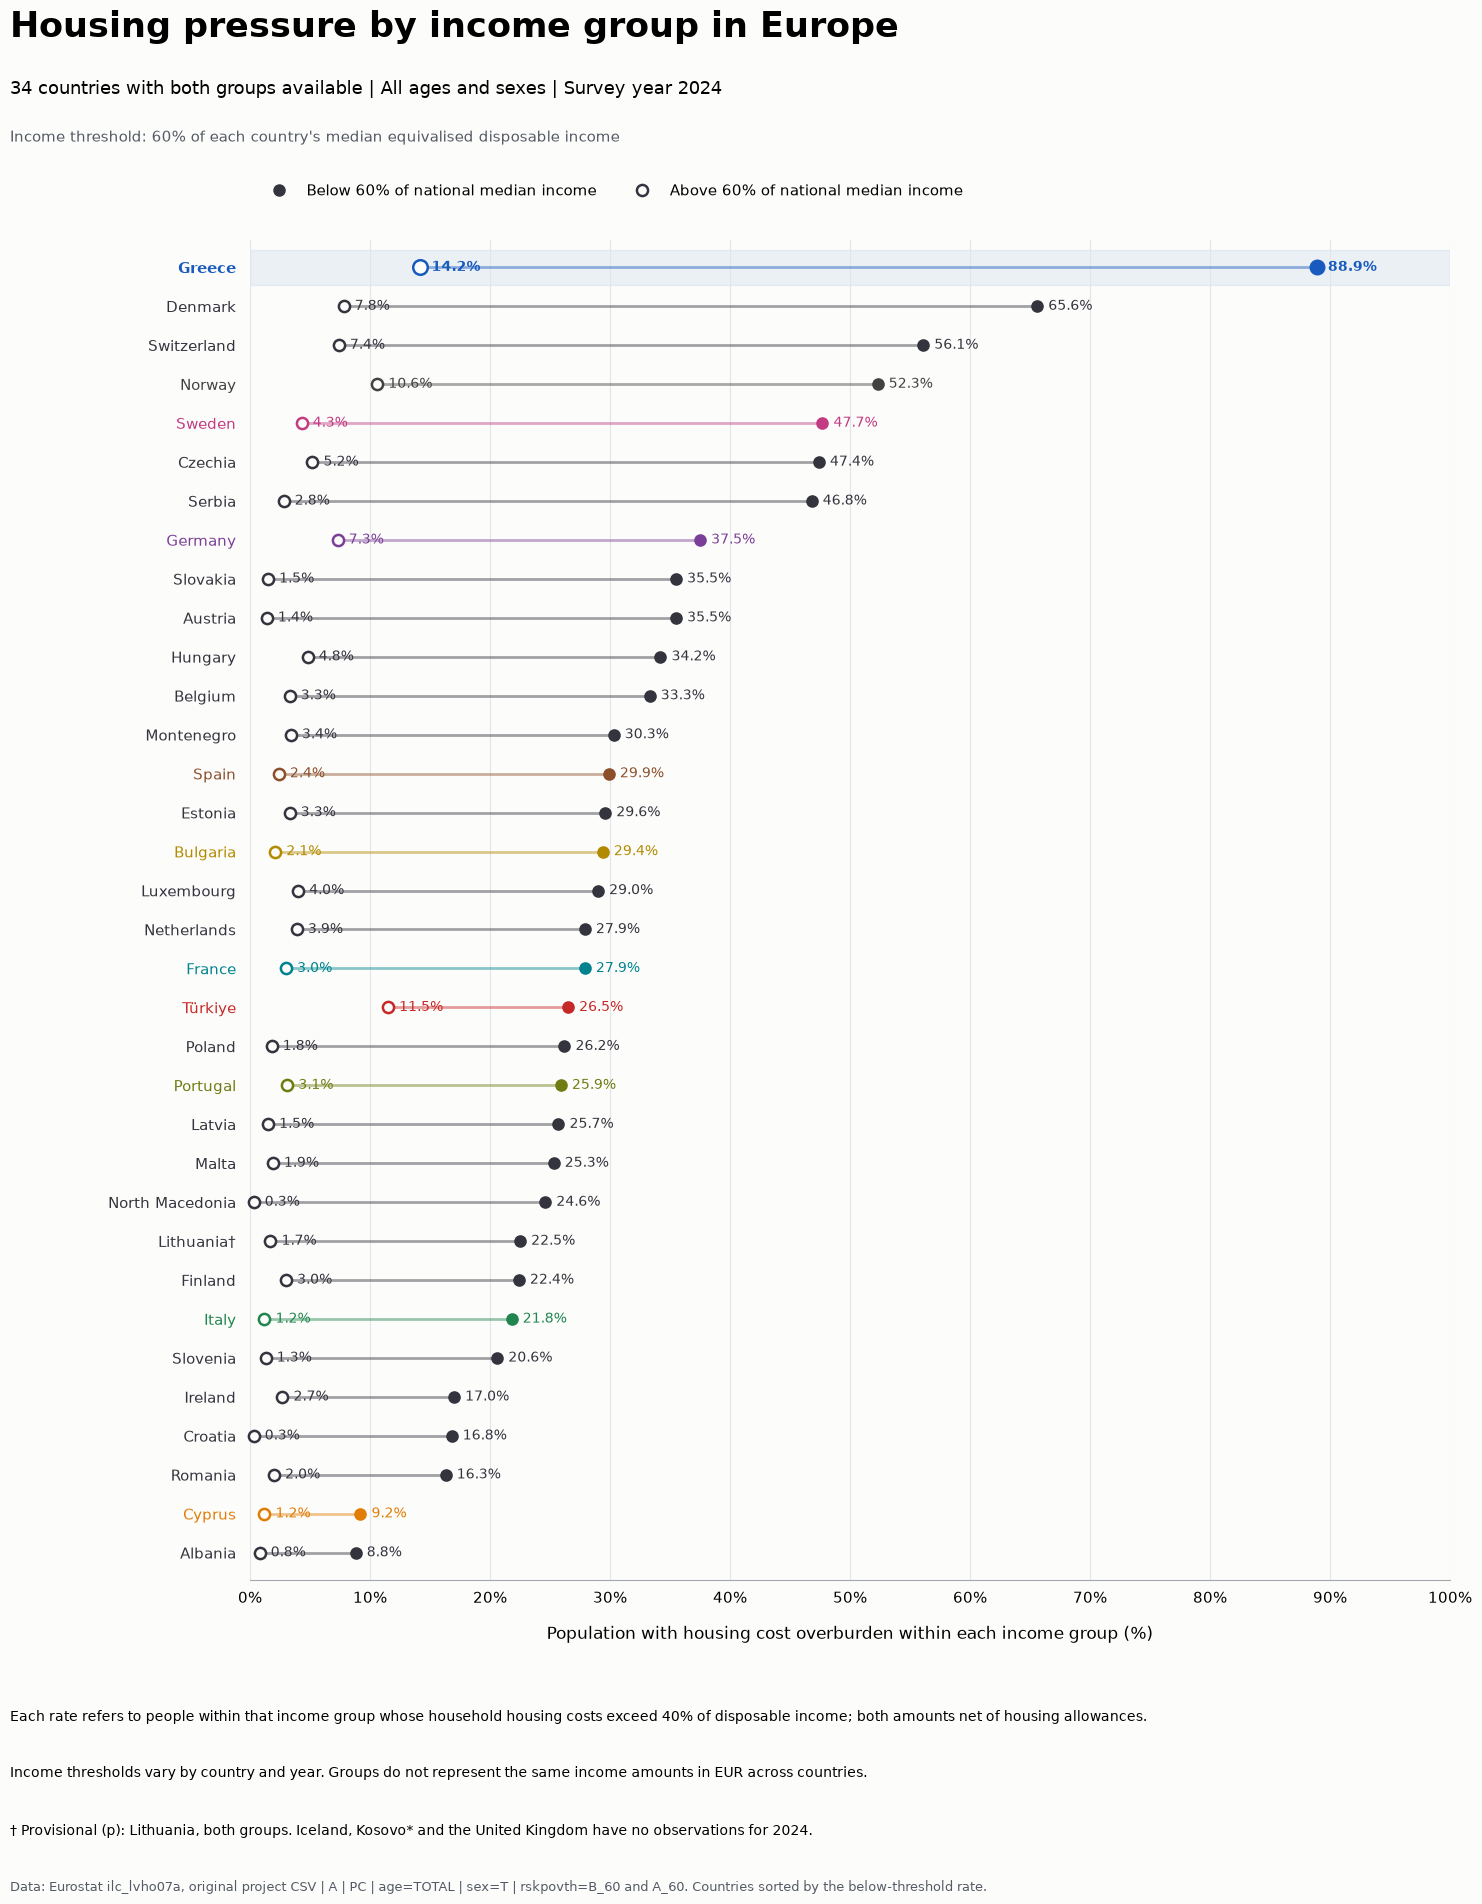

In [30]:
fig, ax = plt.subplots(figsize=(16, 20), facecolor="#FCFCFA")
fig.subplots_adjust(left=0.20, right=0.95, top=0.86, bottom=0.19)
ax.set_facecolor("#FCFCFA")

country_labels = []

for y, ((geo_code, geo_name), row) in enumerate(
    housing_group_plot_2024.iterrows()
):
    color = country_colors.get(geo_code, "#34343F")
    is_greece = geo_code == "EL"

    below = row["B_60"]
    above = row["A_60"]

    flagged = housing_group_flags_2024.loc[
        (geo_code, geo_name)
    ].notna().any()

    country_labels.append(geo_name + ("†" if flagged else ""))

    if is_greece:
        ax.axhspan(
            y - 0.45, y + 0.45,
            color=color, alpha=0.07, zorder=0)

    # Connect the two rates within the same country.
    ax.plot(
        [above, below], [y, y],
        color=color, alpha=0.45, linewidth=2, zorder=2)

    # Filled circle: below the income threshold.
    ax.scatter(
        below, y,
        s=110 if is_greece else 65,
        color=color, edgecolors=color,
        clip_on=False, zorder=4)

    # Open circle: above the income threshold.
    ax.scatter(
        above, y,
        s=110 if is_greece else 65,
        facecolors="#FCFCFA", edgecolors=color,
        linewidths=1.8, clip_on=False, zorder=4)

    for value in [above, below]:
        ax.annotate(
            f"{value:.1f}%",
            xy=(value, y),
            xytext=(8, 0),
            textcoords="offset points",
            ha="left", va="center",
            fontsize=10,
            fontweight="bold" if is_greece else "normal",
            color=color,
            zorder=5)

ax.set_yticks(
    range(len(housing_group_plot_2024)),
    labels=country_labels)

# Country labels follow the same colour mapping as previous figures.
for label, (geo_code, _) in zip(
    ax.get_yticklabels(), housing_group_plot_2024.index
):
    label.set_color(country_colors.get(geo_code, "#34343F"))
    if geo_code == "EL":
        label.set_fontweight("bold")

ax.set_ylim(-0.7, len(housing_group_plot_2024) - 0.3)
ax.invert_yaxis()

ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 10))
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))

ax.set_xlabel(
    "Population with housing cost overburden within each income group (%)",
    fontsize=12, labelpad=14)

ax.tick_params(axis="y", labelsize=11, length=0, pad=10)
ax.tick_params(axis="x", labelsize=11, length=0, pad=8)
ax.grid(axis="x", color="#E2E5EA", linewidth=0.8)
ax.set_axisbelow(True)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#A2A8AE")

legend_handles = [
    Line2D(
        [], [], marker="o", linestyle="None",
        markerfacecolor="#34343F", markeredgecolor="#34343F",
        markersize=8, label="Below 60% of national median income"
    ),
    Line2D(
        [], [], marker="o", linestyle="None",
        markerfacecolor="#FCFCFA", markeredgecolor="#34343F",
        markeredgewidth=1.8, markersize=8,
        label="Above 60% of national median income")]

fig.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.20, 0.895),
    ncols=2, frameon=False, fontsize=11)

fig.suptitle(
    "Housing pressure by income group in Europe",
    x=0.05, y=0.975, ha="left", va="top",
    fontsize=25, fontweight="bold")
fig.text(
    0.05, 0.94,
    "34 countries with both groups available | All ages and sexes | Survey year 2024",
    fontsize=13, va="top")
fig.text(
    0.05, 0.915,
    "Income threshold: 60% of each country's median equivalised disposable income",
    fontsize=11, color="#555B66", va="top")

fig.text(
    0.05, 0.125,
    "Each rate refers to people within that income group whose household housing costs "
    "exceed 40% of disposable income; both amounts net of housing allowances.",
    fontsize=10, va="top")
fig.text(
    0.05, 0.097,
    "Income thresholds vary by country and year. Groups do not represent the same "
    "income amounts in EUR across countries.",
    fontsize=10, va="top")
fig.text(
    0.05, 0.068,
    "† Provisional (p): Lithuania, both groups. Iceland, Kosovo* and the United Kingdom "
    "have no observations for 2024.",
    fontsize=10, va="top")
fig.text(
    0.05, 0.04,
    "Data: Eurostat ilc_lvho07a, original project CSV | A | PC | age=TOTAL | sex=T | "
    "rskpovth=B_60 and A_60. Countries sorted by the below-threshold rate.",
    fontsize=9, color="#555B66", va="top")

fig.savefig(
    "../reports/figures/europe_housing_overburden_income_groups_2024.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

### Key findings (2024)

- Housing cost overburden was higher in the lower-income group in all 34 countries.
- Greece recorded the highest rates in both groups: **88.9% below** and **14.2% above** the threshold of 60% of national median equivalised disposable income.

Thresholds are country-specific. Lithuania’s figures are provisional.

In [31]:
age_income_data = pd.read_csv("../data/processed/ilc_di03_age_groups.csv")

age_names = {
    "Y_LT18": "0–17",
    "Y18-24": "18–24",
    "Y25-49": "25–49",
    "Y50-64": "50–64",
    "Y_GE65": "65+"}
age_codes = list(age_names)

europe_age_2024 = age_income_data.loc[
    (age_income_data["year"] == 2024)
    & (age_income_data["indicator"] == "MED_EI")
    & (age_income_data["unit"] == "EUR")
    & (age_income_data["sex"] == "T")
    & age_income_data["age"].isin(age_codes)
    & ~age_income_data["geo_code"].str.startswith(("EU", "EA"))].copy()

In [32]:
# Use the existing country roster to retain countries absent from the 2024 selection.
age_country_names = (
    europe_income[["geo_code", "geo_name"]]
    .drop_duplicates()
    .set_index("geo_code")["geo_name"]
    .sort_values())

age_values_2024 = europe_age_2024.pivot(
    index="geo_code",
    columns="age",
    values="income"
).reindex(
    index=age_country_names.index,
    columns=age_codes)

age_flags_2024 = europe_age_2024.pivot(
    index="geo_code",
    columns="age",
    values="obs_flag"
).reindex(
    index=age_country_names.index,
    columns=age_codes)

In [37]:
# Retain partial coverage; exclude only countries with no available age-group value.
age_plot_values_2024 = age_values_2024.loc[age_values_2024.notna().any(axis=1)].copy()

print("Countries included:", len(age_plot_values_2024))
print("2024 median income by age group (EUR):")

display(age_country_names.to_frame().join(age_values_2024).rename(columns=age_names))

print("Flagged observations:")
display(
    europe_age_2024.loc[
        europe_age_2024["obs_flag"].notna(),
        ["geo_name", "age_group", "income", "obs_flag"]
    ].sort_values(["geo_name", "age_group"]))

Countries included: 34
2024 median income by age group (EUR):


,geo_name,0–17,18–24,25–49,50–64,65+
geo_code,,,,,,
AL,Albania,4582.0,5011.0,5485.0,5721.0,4208.0
AT,Austria,30361.0,32555.0,33948.0,37109.0,31073.0
BE,Belgium,29440.0,29412.0,33536.0,33889.0,24725.0
BG,Bulgaria,7224.0,7660.0,8665.0,9025.0,6320.0
HR,Croatia,12099.0,13319.0,13708.0,13405.0,8968.0
CY,Cyprus,20180.0,19538.0,21877.0,23227.0,15958.0
CZ,Czechia,14324.0,14796.0,16589.0,17184.0,13057.0
DK,Denmark,35480.0,27963.0,36852.0,43468.0,28631.0
EE,Estonia,17166.0,16195.0,18759.0,17030.0,10820.0


Flagged observations:


,geo_name,age_group,income,obs_flag
21275,Croatia,0–17,12099,b
2739,Croatia,18–24,13319,b
7373,Croatia,25–49,13708,b
12007,Croatia,50–64,13405,b
16641,Croatia,65+,8968,b
21379,Lithuania,0–17,12439,p
2843,Lithuania,18–24,11722,p
7477,Lithuania,25–49,15510,p
12111,Lithuania,50–64,12954,p
16745,Lithuania,65+,8550,p


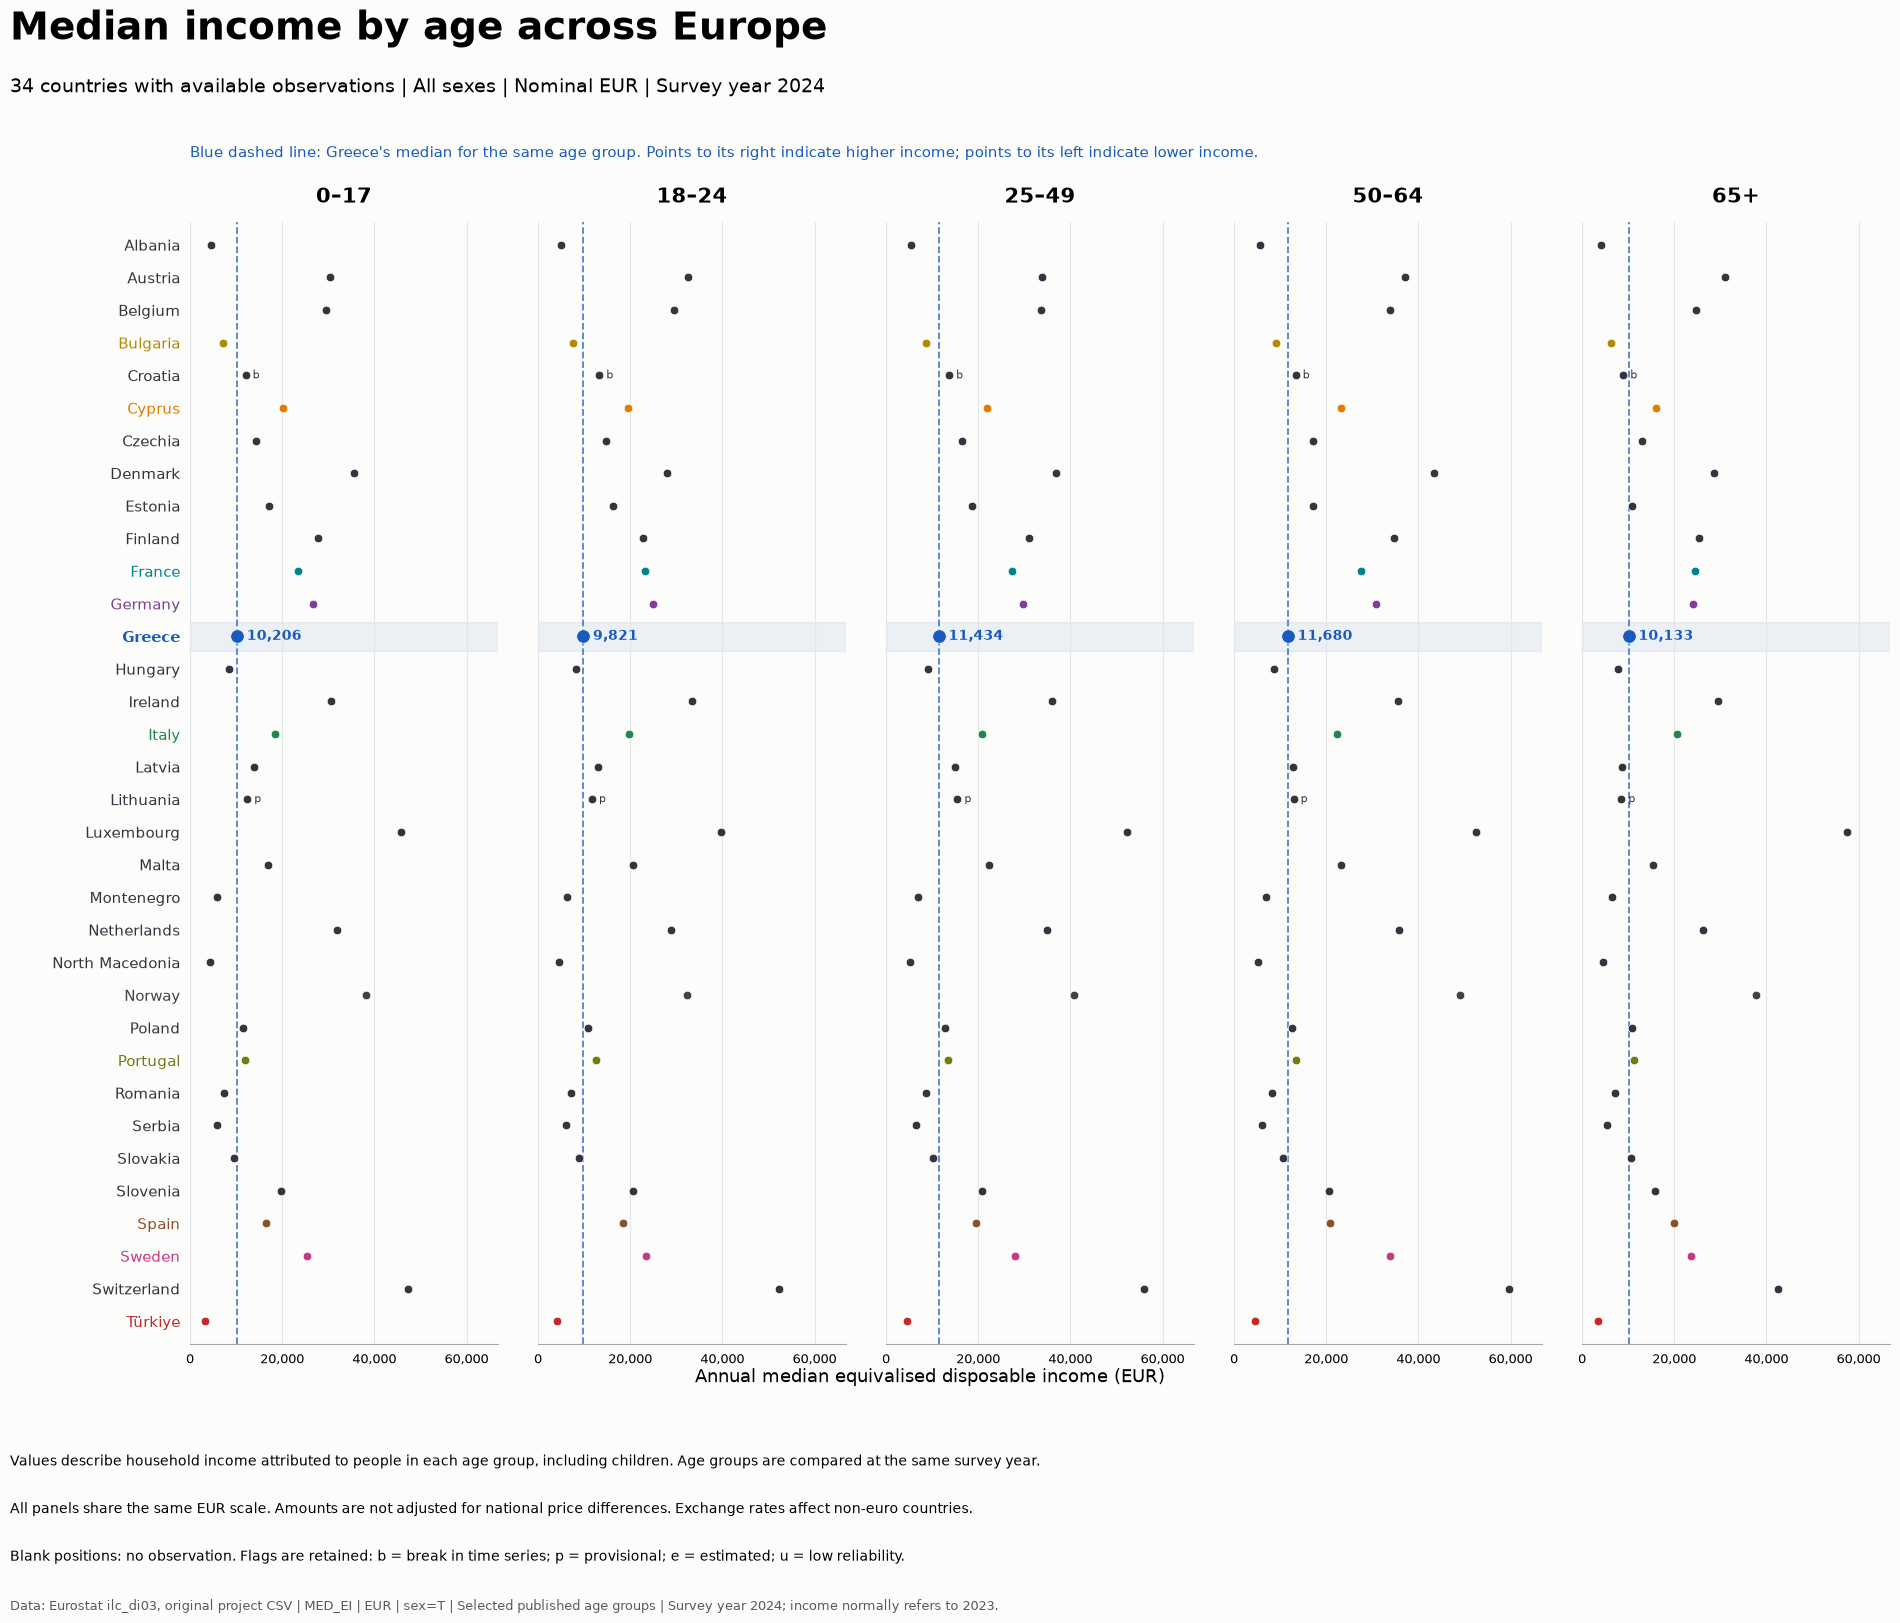

In [38]:
fig, axes = plt.subplots(
    1, 5,
    figsize=(20, 17),
    sharex=True,
    sharey=True,
    facecolor="#FCFCFA")

fig.subplots_adjust(
    left=0.13, right=0.98,
    top=0.85, bottom=0.19,
    wspace=0.13)

plot_countries = age_plot_values_2024.index
greece_y = plot_countries.get_loc("EL")
greece_color = country_colors["EL"]
max_income = age_plot_values_2024.max().max()

for ax, age_code in zip(axes, age_codes):
    ax.set_facecolor("#FCFCFA")

    greece_income = age_plot_values_2024.loc["EL", age_code]

    # Each panel uses Greece's median for the same age group as its reference.
    ax.axvline(
        greece_income,
        color=greece_color,
        linestyle="--",
        linewidth=1.3,
        alpha=0.75,
        zorder=1)

    ax.axhspan(
        greece_y - 0.45, greece_y + 0.45,
        color=greece_color, alpha=0.07, zorder=0    )

    for y, geo_code in enumerate(plot_countries):
        value = age_plot_values_2024.loc[geo_code, age_code]

        # Missing observations have no point.
        if pd.isna(value):
            continue

        color = country_colors.get(geo_code, "#34343F")
        is_greece = geo_code == "EL"

        ax.scatter(
            value, y,
            s=95 if is_greece else 38,
            color=color,
            edgecolors="#FCFCFA",
            linewidths=0.5,
            zorder=4)

        if is_greece:
            ax.annotate(
                f"{value:,.0f}",
                xy=(value, y),
                xytext=(7, 0),
                textcoords="offset points",
                ha="left", va="center",
                fontsize=10,
                fontweight="bold",
                color=greece_color,
                zorder=5)

        flag = age_flags_2024.loc[geo_code, age_code]

        if pd.notna(flag):
            ax.annotate(
                str(flag),
                xy=(value, y),
                xytext=(5, 0),
                textcoords="offset points",
                ha="left", va="center",
                fontsize=8,
                color=color,
                zorder=5)

    ax.set_title(
        age_names[age_code],
        fontsize=15, fontweight="bold", pad=14)

    ax.set_xlim(0, max_income * 1.12)
    ax.set_ylim(len(plot_countries) - 0.3, -0.7)

    ax.xaxis.set_major_locator(MultipleLocator(20000))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

    ax.tick_params(
        axis="both", labelsize=9, length=0, pad=7)
    ax.grid(axis="x", color="#E2E5EA", linewidth=0.8)
    ax.set_axisbelow(True)

    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#A2A8AE")

axes[0].set_yticks(
    range(len(plot_countries)),
    labels=age_country_names.loc[plot_countries].tolist())
axes[0].tick_params(axis="y", labelsize=11)

for label, geo_code in zip(
    axes[0].get_yticklabels(), plot_countries
):
    label.set_color(country_colors.get(geo_code, "#34343F"))
    if geo_code == "EL":
        label.set_fontweight("bold")

fig.suptitle(
    "Median income by age across Europe",
    x=0.04, y=0.975, ha="left", va="top",
    fontsize=28, fontweight="bold")

fig.text(
    0.04, 0.935,
    f"{len(plot_countries)} countries with available observations | "
    "All sexes | Nominal EUR | Survey year 2024",
    fontsize=14, va="top")

fig.text(
    0.13, 0.895,
    "Blue dashed line: Greece's median for the same age group. "
    "Points to its right indicate higher income; points to its left indicate lower income.",
    fontsize=11, color=greece_color, va="top")

fig.supxlabel(
    "Annual median equivalised disposable income (EUR)",
    y=0.165, fontsize=13)

fig.text(
    0.04, 0.125,
    "Values describe household income attributed to people in each age group, "
    "including children. Age groups are compared at the same survey year.",
    fontsize=10, va="top")
fig.text(
    0.04, 0.097,
    "All panels share the same EUR scale. Amounts are not adjusted for national "
    "price differences. Exchange rates affect non-euro countries.",
    fontsize=10, va="top")
fig.text(
    0.04, 0.069,
    "Blank positions: no observation. Flags are retained: b = break in time series; "
    "p = provisional; e = estimated; u = low reliability.",
    fontsize=10, va="top")
fig.text(
    0.04, 0.04,
    "Data: Eurostat ilc_di03, original project CSV | MED_EI | EUR | sex=T | "
    "Selected published age groups | Survey year 2024; income normally refers to 2023.",
    fontsize=9, color="#555B66", va="top")

fig.savefig(
    "../reports/figures/europe_median_income_by_age_2024_eur.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

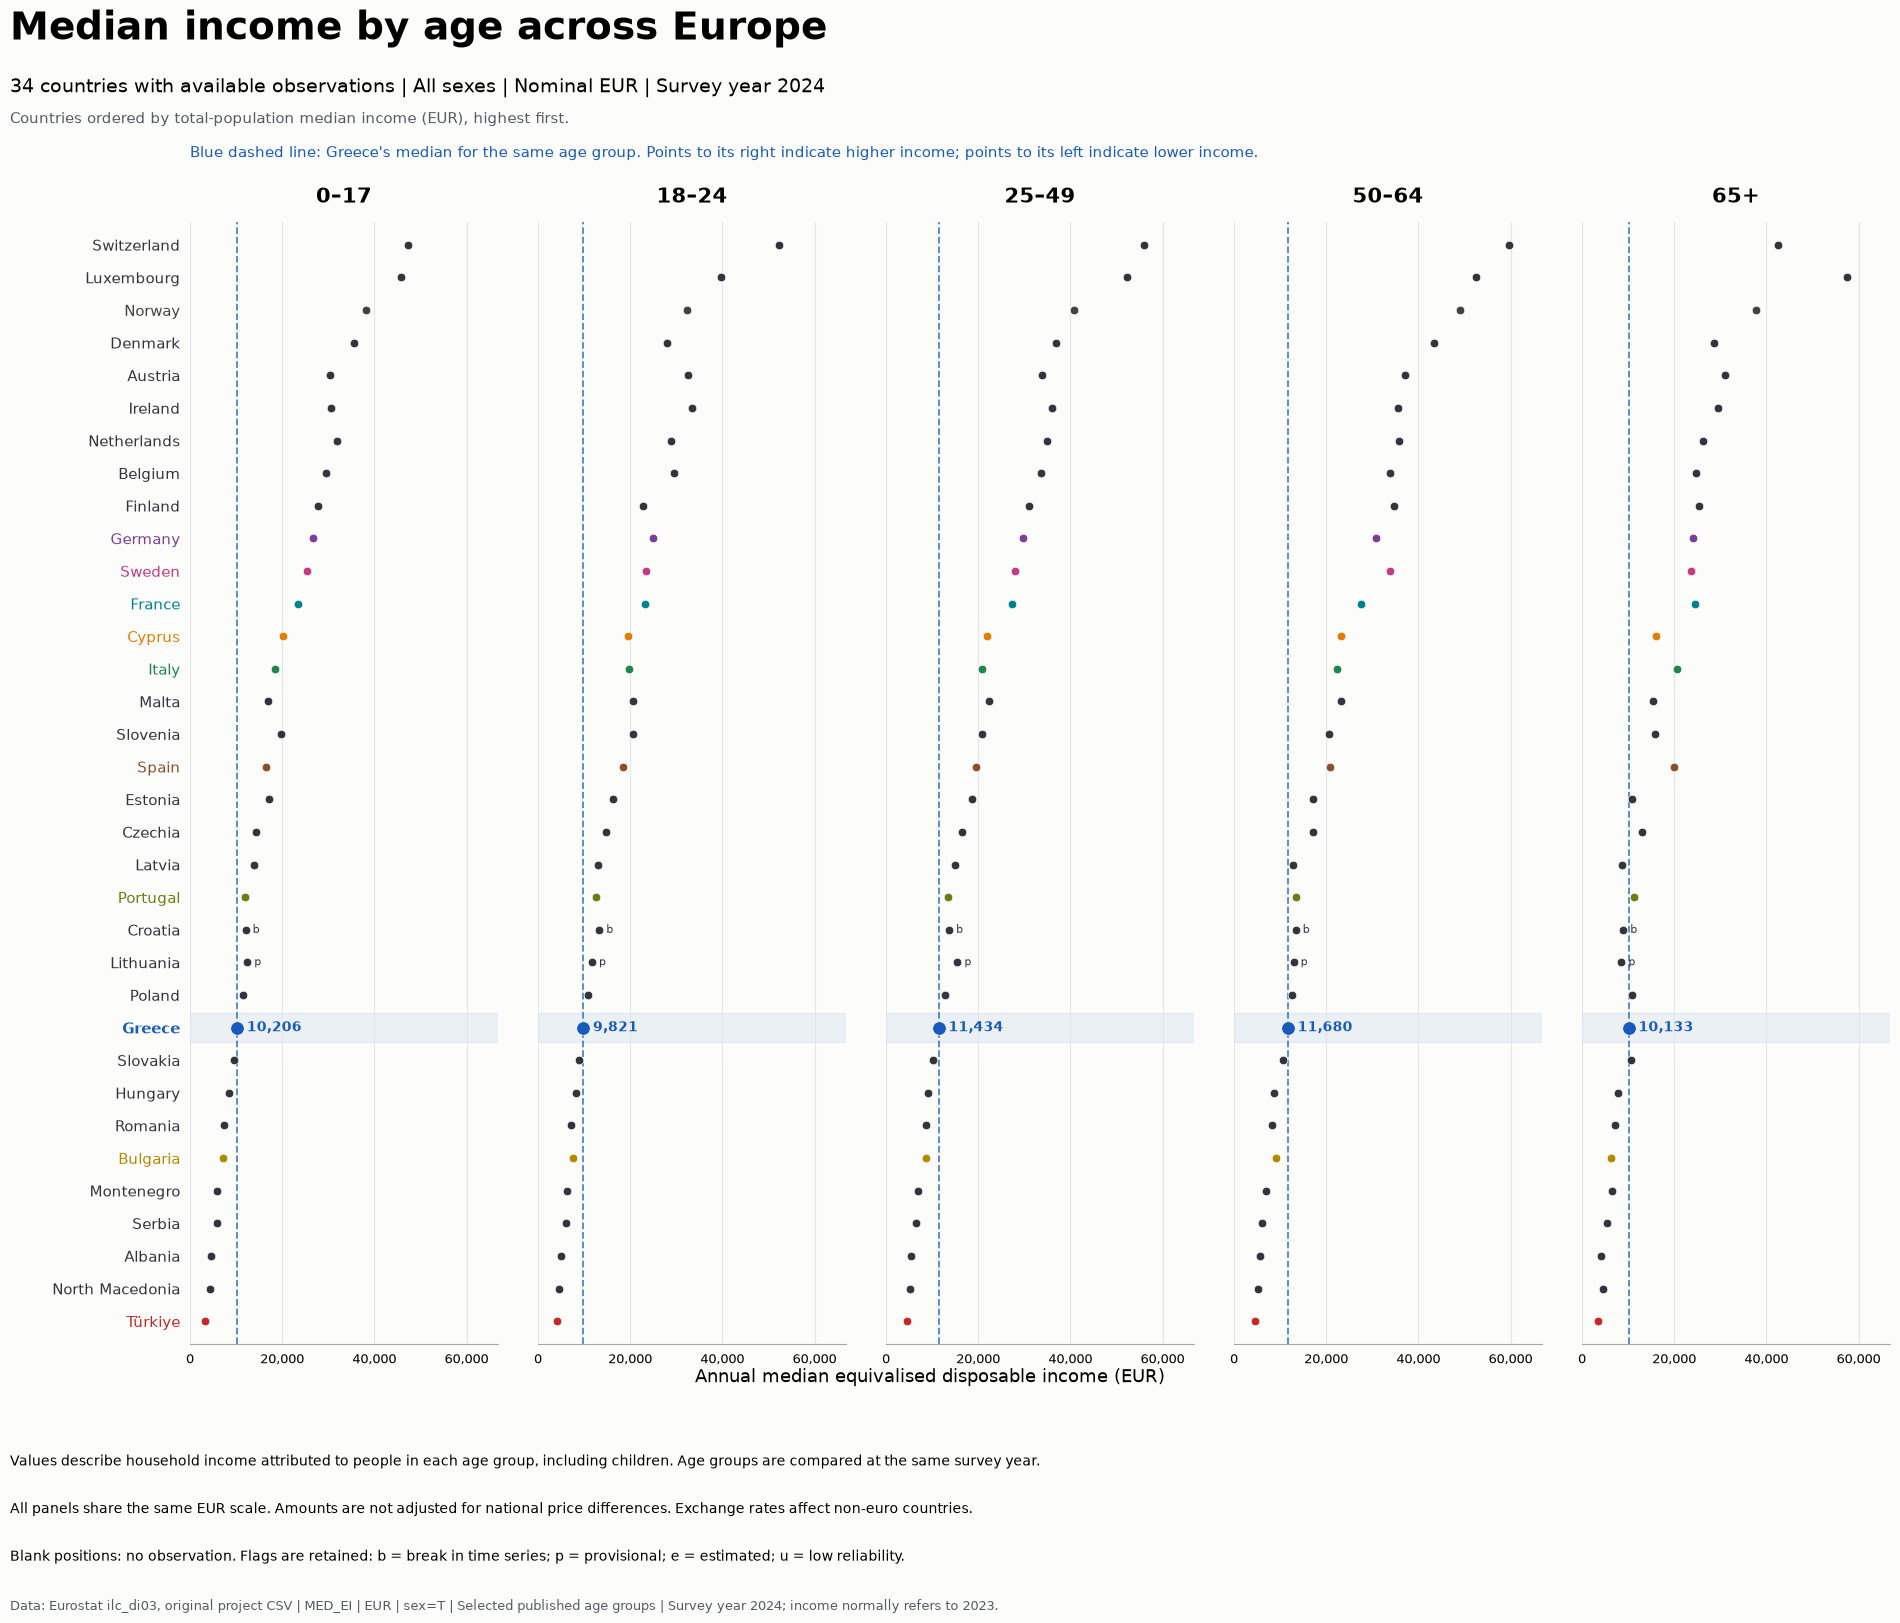

In [39]:
# Order countries by their published total-population median income.
total_income_order_2024 = (
    europe_income.loc[
        (europe_income["year"] == 2024)
        & (europe_income["indicator"] == "MED_EI")
        & (europe_income["unit"] == "EUR")
        & (europe_income["age"] == "TOTAL")
        & (europe_income["sex"] == "T")
    ]
    .set_index("geo_code")["income"]
    .reindex(age_plot_values_2024.index)
    .sort_values(ascending=False, na_position="last"))

# Apply the same country order to all five panels.
age_plot_sorted_2024 = age_plot_values_2024.reindex(
    total_income_order_2024.index)

fig, axes = plt.subplots(
    1, 5,
    figsize=(20, 17),
    sharex=True,
    sharey=True,
    facecolor="#FCFCFA")

fig.subplots_adjust(
    left=0.13, right=0.98,
    top=0.85, bottom=0.19,
    wspace=0.13)

plot_countries = age_plot_sorted_2024.index
greece_y = plot_countries.get_loc("EL")
greece_color = country_colors["EL"]
max_income = age_plot_sorted_2024.max().max()

for ax, age_code in zip(axes, age_codes):
    ax.set_facecolor("#FCFCFA")

    greece_income = age_plot_sorted_2024.loc["EL", age_code]

    # Each panel references Greece's median for the same age group.
    ax.axvline(
        greece_income,
        color=greece_color,
        linestyle="--",
        linewidth=1.3,
        alpha=0.75,
        zorder=1)

    ax.axhspan(
        greece_y - 0.45, greece_y + 0.45,
        color=greece_color, alpha=0.07, zorder=0)

    for y, geo_code in enumerate(plot_countries):
        value = age_plot_sorted_2024.loc[geo_code, age_code]

        if pd.isna(value):
            continue

        color = country_colors.get(geo_code, "#34343F")
        is_greece = geo_code == "EL"

        ax.scatter(
            value, y,
            s=95 if is_greece else 38,
            color=color,
            edgecolors="#FCFCFA",
            linewidths=0.5,
            zorder=4)

        if is_greece:
            ax.annotate(
                f"{value:,.0f}",
                xy=(value, y),
                xytext=(7, 0),
                textcoords="offset points",
                ha="left", va="center",
                fontsize=10,
                fontweight="bold",
                color=greece_color,
                zorder=5)

        flag = age_flags_2024.loc[geo_code, age_code]

        if pd.notna(flag):
            ax.annotate(
                str(flag),
                xy=(value, y),
                xytext=(5, 0),
                textcoords="offset points",
                ha="left", va="center",
                fontsize=8,
                color=color,
                zorder=5)

    ax.set_title(age_names[age_code], fontsize=15, fontweight="bold", pad=14)

    ax.set_xlim(0, max_income * 1.12)
    ax.set_ylim(len(plot_countries) - 0.3, -0.7)

    ax.xaxis.set_major_locator(MultipleLocator(20000))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

    ax.tick_params(axis="both", labelsize=9, length=0, pad=7)
    ax.grid(axis="x", color="#E2E5EA", linewidth=0.8)
    ax.set_axisbelow(True)

    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#A2A8AE")

axes[0].set_yticks(
    range(len(plot_countries)),
    labels=age_country_names.loc[plot_countries].tolist())
axes[0].tick_params(axis="y", labelsize=11)

for label, geo_code in zip(
    axes[0].get_yticklabels(), plot_countries
):
    label.set_color(country_colors.get(geo_code, "#34343F"))
    if geo_code == "EL":
        label.set_fontweight("bold")

fig.suptitle(
    "Median income by age across Europe",
    x=0.04, y=0.975, ha="left", va="top",
    fontsize=28, fontweight="bold")

fig.text(
    0.04, 0.935,
    f"{len(plot_countries)} countries with available observations | "
    "All sexes | Nominal EUR | Survey year 2024",
    fontsize=14, va="top")

fig.text(
    0.04, 0.915,
    "Countries ordered by total-population median income (EUR), highest first.",
    fontsize=11, color="#555B66", va="top")

fig.text(
    0.13, 0.895,
    "Blue dashed line: Greece's median for the same age group. "
    "Points to its right indicate higher income; points to its left indicate lower income.",
    fontsize=11, color=greece_color, va="top")

fig.supxlabel(
    "Annual median equivalised disposable income (EUR)",
    y=0.165, fontsize=13)

fig.text(
    0.04, 0.125,
    "Values describe household income attributed to people in each age group, "
    "including children. Age groups are compared at the same survey year.",
    fontsize=10, va="top")
fig.text(
    0.04, 0.097,
    "All panels share the same EUR scale. Amounts are not adjusted for national "
    "price differences. Exchange rates affect non-euro countries.",
    fontsize=10, va="top")
fig.text(
    0.04, 0.069,
    "Blank positions: no observation. Flags are retained: b = break in time series; "
    "p = provisional; e = estimated; u = low reliability.",
    fontsize=10, va="top")
fig.text(
    0.04, 0.04,
    "Data: Eurostat ilc_di03, original project CSV | MED_EI | EUR | sex=T | "
    "Selected published age groups | Survey year 2024; income normally refers to 2023.",
    fontsize=9, color="#555B66", va="top")

fig.savefig(
    "../reports/figures/europe_median_income_by_age_2024_eur.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

### HICP

In [45]:
real_income_data = pd.read_csv("../data/processed/ilc_di03_real_input_2019_2023.csv")

hicp_real_data = pd.read_csv("../data/processed/hicp_europe.csv").rename(columns={"price_year": "income_year"})

real_income_data = real_income_data.merge(
    hicp_real_data[
        [
            "geo_code", "income_year", "hicp",
            "hicp_flag", "hicp_flag_description"
        ]
    ], on=["geo_code", "income_year"], how="left")

In [46]:
# Retain the full country roster when checking endpoint availability.
real_country_roster = (europe_income[["geo_code", "geo_name"]].drop_duplicates().set_index("geo_code"))

start_values = (
    real_income_data.loc[
        real_income_data["income_year"] == 2019,
        ["geo_code", "income_for_deflation", "hicp"]
    ]
    .set_index("geo_code")
    .rename(columns={
        "income_for_deflation": "income_2019",
        "hicp": "hicp_2019"
    }))

end_values = (
    real_income_data.loc[
        real_income_data["income_year"] == 2023,
        ["geo_code", "income_for_deflation", "hicp"]
    ]
    .set_index("geo_code")
    .rename(columns={
        "income_for_deflation": "income_2023",
        "hicp": "hicp_2023"
    }))

real_comparison = (real_country_roster.join(start_values).join(end_values))

required_values = ["income_2019", "income_2023", "hicp_2019", "hicp_2023"]

has_endpoints = real_comparison[required_values].notna().all(axis=1)

print("Excluded countries: missing income or HICP at either endpoint.")
display(
    real_comparison.loc[
        ~has_endpoints,
        ["geo_name"] + required_values
    ])

Excluded countries: missing income or HICP at either endpoint.


,geo_name,income_2019,income_2023,hicp_2019,hicp_2023
geo_code,,,,,
IS,Iceland,4933016.0,NaN,77.04,NaN
UK,United Kingdom,NaN,NaN,NaN,NaN
XK,Kosovo*,NaN,NaN,NaN,NaN


In [47]:
# Endpoint comparisons require both income and price values at both dates.
real_comparison = real_comparison.loc[has_endpoints].copy()

real_comparison["nominal_change_pct"] = 100 * (real_comparison["income_2023"] / real_comparison["income_2019"] - 1)

real_comparison["price_change_pct"] = 100 * (real_comparison["hicp_2023"] / real_comparison["hicp_2019"] - 1)

real_comparison["real_change_pct"] = 100 * ((real_comparison["income_2023"] / real_comparison["income_2019"]) / (real_comparison["hicp_2023"] / real_comparison["hicp_2019"]) - 1)


In [48]:
# Keep source flags from every available year in the comparison period.
real_period_flags = real_income_data.loc[
    real_income_data["income_flag"].notna()
    | real_income_data["hicp_flag"].notna(),
    [
        "geo_code", "geo_name", "survey_year", "income_year",
        "income_flag", "income_flag_description",
        "hicp_flag", "hicp_flag_description"
    ]].sort_values(["geo_name", "income_year"])

real_comparison["flagged"] = real_comparison.index.isin(real_period_flags["geo_code"])

real_comparison = real_comparison.sort_values("real_change_pct", ascending=False)

print("Countries included:", len(real_comparison))
display(
    real_comparison[
        [
            "geo_name", "nominal_change_pct", "price_change_pct",
            "real_change_pct", "flagged"
        ]
    ].round(2))

Countries included: 34


,geo_name,nominal_change_pct,price_change_pct,real_change_pct,flagged
geo_code,,,,,
AL,Albania,74.15,17.28,48.49,False
TR,Türkiye,421.92,256.05,46.58,False
RO,Romania,91.45,30.96,46.19,False
ME,Montenegro,68.75,24.14,35.94,False
BG,Bulgaria,69.36,27.77,32.55,False
HR,Croatia,58.87,23.18,28.98,True
MK,North Macedonia,61.93,30.09,24.48,True
RS,Serbia,64.23,32.58,23.87,False
LU,Luxembourg,34.23,15.19,16.53,True


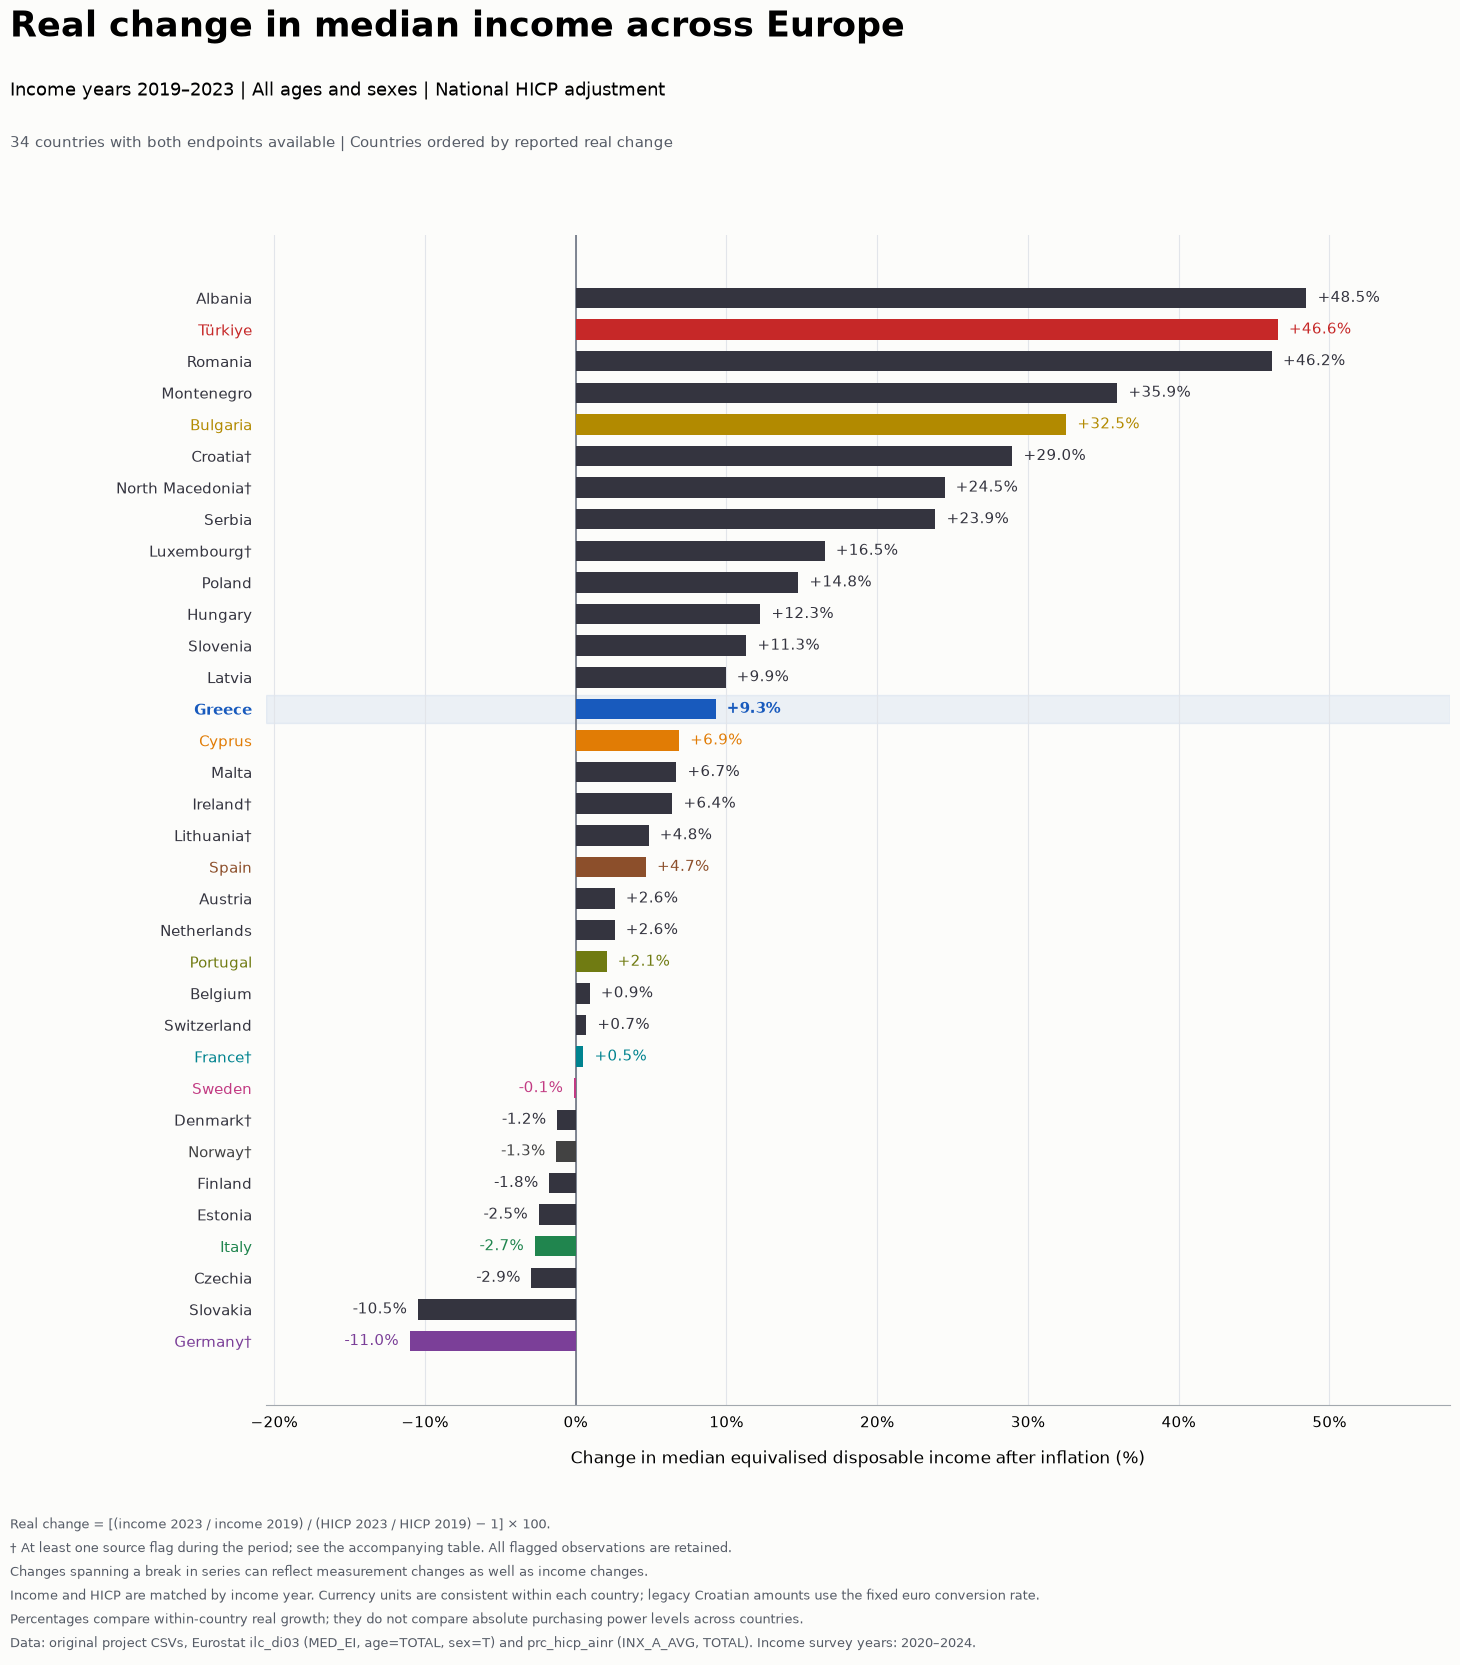

In [49]:
fig, ax = plt.subplots(figsize=(16, 18), facecolor="#FCFCFA")
fig.subplots_adjust(left=0.21, right=0.95, top=0.85, bottom=0.20)
ax.set_facecolor("#FCFCFA")

plot_codes = real_comparison.index
plot_colors = [
    country_colors.get(code, "#34343F")
    for code in plot_codes]

plot_labels = [
    row["geo_name"] + ("†" if row["flagged"] else "")
    for _, row in real_comparison.iterrows()]

greece_y = plot_codes.get_loc("EL")

ax.axhspan(
    greece_y - 0.45, greece_y + 0.45,
    color=country_colors["EL"], alpha=0.07, zorder=0)

ax.barh(
    range(len(real_comparison)),
    real_comparison["real_change_pct"],
    color=plot_colors,
    height=0.65,
    zorder=3)

ax.axvline(0, color="#6B7280", linewidth=1.2, zorder=2)

for y, (geo_code, row) in enumerate(real_comparison.iterrows()):
    value = row["real_change_pct"]
    is_greece = geo_code == "EL"

    ax.annotate(
        f"{value:+.1f}%",
        xy=(value, y),
        xytext=(8 if value >= 0 else -8, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=11,
        fontweight="bold" if is_greece else "normal",
        color=country_colors.get(geo_code, "#34343F"))

ax.set_yticks(
    range(len(real_comparison)),
    labels=plot_labels)
ax.invert_yaxis()

for label, geo_code in zip(ax.get_yticklabels(), plot_codes):
    label.set_color(country_colors.get(geo_code, "#34343F"))
    if geo_code == "EL":
        label.set_fontweight("bold")

lower = min(0, real_comparison["real_change_pct"].min())
upper = max(0, real_comparison["real_change_pct"].max())
padding = (upper - lower) * 0.16

ax.set_xlim(lower - padding, upper + padding)
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))

ax.set_xlabel(
    "Change in median equivalised disposable income after inflation (%)",
    fontsize=12, labelpad=14)

ax.tick_params(axis="y", labelsize=11, length=0, pad=10)
ax.tick_params(axis="x", labelsize=11, length=0, pad=8)
ax.grid(axis="x", color="#E2E5EA", linewidth=0.8)
ax.set_axisbelow(True)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#A2A8AE")

fig.suptitle(
    "Real change in median income across Europe",
    x=0.05, y=0.975, ha="left", va="top",
    fontsize=25, fontweight="bold")

fig.text(
    0.05, 0.935,
    "Income years 2019–2023 | All ages and sexes | National HICP adjustment",
    fontsize=13, va="top")

fig.text(
    0.05, 0.905,
    f"{len(real_comparison)} countries with both endpoints available | "
    "Countries ordered by reported real change",
    fontsize=11, color="#555B66", va="top")

fig.text(
    0.05, 0.14,
    "Real change = [(income 2023 / income 2019) / (HICP 2023 / HICP 2019) − 1] × 100.\n"
    "† At least one source flag during the period; see the accompanying table. "
    "All flagged observations are retained.\n"
    "Changes spanning a break in series can reflect measurement changes as well as income changes.\n"
    "Income and HICP are matched by income year. Currency units are consistent within each country; "
    "legacy Croatian amounts use the fixed euro conversion rate.\n"
    "Percentages compare within-country real growth; they do not compare absolute purchasing power levels across countries.\n"
    "Data: original project CSVs, Eurostat ilc_di03 (MED_EI, age=TOTAL, sex=T) "
    "and prc_hicp_ainr (INX_A_AVG, TOTAL). Income survey years: 2020–2024.",
    fontsize=9.5, color="#555B66",
    va="top", linespacing=1.8)

fig.savefig(
    "../reports/figures/europe_real_median_income_change_2019_2023.png",
    dpi=300,
    facecolor=fig.get_facecolor())

plt.show()

### Europe: closing notes

- Between income years 2019 and 2023, Greece’s median income increased by **23.56% nominally** and **9.29% after inflation**. Consumer prices rose by **13.06%**.
- Real income growth varied substantially. Albania (**48.49%**), Türkiye (**46.58%**) and Romania (**46.19%**) recorded the largest increases among the 34 countries.
- Real income declined in several countries, including Slovakia (**−10.46%**) and Germany (**−11.01%**). Germany’s series includes a break flag.
- Despite its income growth, Greece recorded the highest housing cost overburden in the 2024 comparison: **28.9% overall**, reaching **88.9% among people below the national income threshold**.

Growth rates describe changes within countries, not differences in absolute purchasing power. Source flags are retained; breaks in series and provisional observations limit comparability.